# **Project Name**    -

##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual/Team
##### **Team Member 1 -**
##### **Team Member 2 -**
##### **Team Member 3 -**
##### **Team Member 4 -**

# **Project Summary -**

# Amazon Prime TV Shows and Movies

### *Machine Learning Capstone Project — Summary Report*

**Exploratory Data Analysis · Hypothesis Testing · Predictive Modeling**

---

This end-to-end Machine Learning capstone project analyzes the Amazon Prime TV Shows and Movies dataset for the United States streaming market. The objective is to evaluate content-catalogue trends, examine the factors influencing critical reception, and build a predictive machine learning model that can flag likely "hit" content using only information that is knowable before a title is acquired or released — deliberately avoiding metrics that are only available after audiences have already engaged with a title.

## 1. Dataset Architecture & Overview

- **titles.csv:** 9,871 titles across 15 attributes, including content format (`type`), release year, runtime, genres, age certifications, production countries, seasons, IMDb scores/votes, and TMDB popularity/ratings.
- **credits.csv:** 124,235 credit records detailing cast and crew members, role designations (`ACTOR` or `DIRECTOR`), character names, and unique person identifiers.
- **Catalogue distribution:** Feature films dominate the catalogue, accounting for **8,514 movies (~86.3%)**, compared to **1,357 TV shows (~13.7%)**.
- **Missing-value profile:** Missing values in `seasons` correspond exclusively to movies (a structural, not a genuine, gap — the concept simply doesn't apply). Missing entries in `age_certification` represent unrated titles (~64% of rows), while missing `imdb_score`/`imdb_votes`/`tmdb_score` reflect titles without registered reviews.

## 2. Data Wrangling & Feature Engineering

- **Relational aggregation:** Merged cast and crew records from `credits.csv` to calculate `cast_size` and `crew_size` per title — both legitimate, pre-release-known features.
- **Imputation logic:** Populated `seasons` for movies with `0` (structural fix, not imputation of genuinely missing data), filled missing `age_certification` with an explicit `'Unknown'` category, and imputed the remaining skewed numeric predictors (`imdb_votes`, `tmdb_popularity`, `tmdb_score`) using the column median, which is robust to outliers.
- **Outlier treatment:** Applied IQR-based capping (winsorization) to `runtime` rather than deleting extreme values, preserving legitimate long-form/short-form content while limiting its leverage on the model.
- **NLP & text preprocessing:** Cleaned title synopses (contraction expansion, lowercasing, punctuation/URL/digit removal, stop-word elimination, lightweight rule-based stemming) and extracted contextual signal via a 500-feature TF-IDF vectorizer, compressed to 8 dense components using Truncated SVD for dimensionality reduction.
- **Target formulation:** Formulated a binary classification task — `is_hit = 1` if `imdb_score >= 7.0`, else `0` — to predict above-average critical reception for content-acquisition decisions.
- **Leakage control:** `imdb_votes`, `tmdb_popularity`, and `tmdb_score` were deliberately excluded from the model's feature set. These are post-release audience-engagement metrics — a title only accumulates them after being watched and rated — so including them would leak information about the very outcome being predicted and defeat the purpose of a pre-acquisition screening tool.

## 3. Exploratory Data Analysis (EDA) — Key Findings

- **Format performance disparity:** TV shows exhibit substantially higher critical reception (mean IMDb score ≈ **7.12**) than feature films (mean IMDb score ≈ **5.80**), and this gap holds consistently across the top genres, not just in aggregate.
- **Genre dominance:** The catalogue is led by Drama (4,762 titles), Comedy (2,987 titles), and Thriller (2,119 titles); Documentary, History, and Reality content rate highest on average despite smaller catalogue shares.
- **Geographic sourcing:** The United States is the primary producer (5,331 titles), followed by India (1,072 titles) and the United Kingdom (928 titles).
- **Runtime clustering:** Most content clusters between 65–105 minutes, consistent with standard feature-film length; a long right tail of longer titles was treated as outliers.
- **Cross-platform agreement:** IMDb votes and TMDB popularity move together on a log-log scale, confirming the two independent platforms broadly agree on which titles generate audience buzz — though neither is used as a model input, for the leakage reasons noted above.

## 4. Hypothesis Testing

Three hypotheses were formally tested against the cleaned dataset, each using a test appropriate to its variable types:

| Hypothesis | Statistical Test | Result |
|---|---|---|
| Movies vs TV Shows differ in mean IMDb score | Welch's two-sample t-test | Rejected H0 (p ≈ 3×10⁻²⁰³) |
| Age certification is associated with "hit" status | Chi-square test of independence | Rejected H0 (p ≈ 6×10⁻¹²⁵) |
| Mean IMDb score differs across top production countries | One-way ANOVA | Rejected H0 (p ≈ 2×10⁻⁴⁸) |

## 5. Machine Learning Modeling & Results

Three classification models were implemented, cross-validated, and tuned via `RandomizedSearchCV` (3-fold stratified CV, optimizing F1-score given the ~75/25 class imbalance):

- **Logistic Regression (baseline):** A fast, directly interpretable linear reference model.
- **Random Forest Classifier:** Captured non-linear interactions across genre, cast size, and duration; achieved the highest accuracy and precision but the weakest recall on the Hit class.
- **Gradient Boosting Classifier (final model):** Delivered the best overall balance — highest ROC-AUC (~0.83), highest F1-score (~0.60), and markedly better recall (~0.70) on the Hit class than Random Forest, making it the most useful model for a "don't miss a future hit" acquisition use case.

| Model (tuned) | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.754 | 0.504 | 0.696 | 0.585 | 0.800 |
| Random Forest | 0.805 | 0.635 | 0.506 | 0.563 | 0.829 |
| **Gradient Boosting (Final)** | **0.764** | **0.519** | **0.698** | **0.596** | **0.831** |

- **Top feature drivers (permutation importance):** primary genre (particularly documentary/horror indicators), cast size, runtime, content age, and several description-derived text components — all genuinely knowable before a title is acquired, consistent with the leakage-free design of the model.
- **Deployment readiness:** The final model was serialized with both `pickle` and `joblib`, reloaded, and sanity-checked against unseen held-out rows to confirm consistent predictions after reloading.

## 6. Business Impact & Strategic Recommendations

- **Prioritize episodic series:** TV shows maintain higher and more consistent audience/critical satisfaction across virtually every genre examined, making continued investment in shows a stronger lever for subscriber engagement and retention than further movie-heavy expansion.
- **Expand under-leveraged genres:** Documentary and history content over-perform their comparatively small catalogue share — a promising, under-tapped area for targeted content investment.
- **Pre-acquisition screening:** The hit-prediction model can support a pre-licensing screening step — flagging promising candidate titles for closer human review using only metadata available at acquisition time, before any post-release audience data exists.
- **Curation for new/unrated content:** Given that ~64% of titles carry no age certification and score variance is wider among less-established content, stricter editorial review is recommended for unrated or newly sourced packages before wide platform placement.

## 7. Limitations & Future Scope

- **Limitations:** IMDb score is an imperfect proxy for true commercial performance (it doesn't capture watch-time, completion rate, or subscriber retention); the dataset has no visibility into titles that were evaluated but never acquired, so the model cannot learn from true negatives outside the platform; and substantial missingness in some columns (notably `age_certification`) required imputation that inevitably introduces some noise.
- **Future scope:** Incorporate true platform engagement metrics as the modeling target if such data becomes available; explore richer, transformer-based text embeddings for synopsis text; and extend the credits data to capture star-power effects (e.g. flagging titles featuring previously "hit" actors or directors) as an additional engineered feature.

---

*Note: this report reflects the leakage-free classification model actually trained and evaluated end-to-end in the accompanying notebook (target threshold: `imdb_score >= 7.0`; excludes post-release engagement metrics from the feature set).*

# **GitHub Link -**

# **Problem Statement**


This dataset was created to analyze all shows available on Amazon Prime Video, allowing us to extract valuable insights such as:  

1. Content Diversity: What genres and categories dominate the platform?  

2. Regional Availability: How does content distribution vary across different regions?  

3. Trends Over Time: How has Amazon Prime's content library evolved?  

4. IMDb Ratings & Popularity: What are the highest-rated or most popular shows on the platform?  

By analyzing this dataset, businesses, content creators, and data analysts can uncover key trends that influence subscription growth, user engagement, and content investment strategies in the streaming industry.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [6]:
# Import Libraries
import warnings
warnings.filterwarnings('ignore')

import ast
import re
import time
import pickle

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      RandomizedSearchCV, cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

# Plot aesthetics
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


### Dataset Loading

In [8]:
# Load Dataset
# The project ships with two CSV files:
#   titles.csv  -> one row per Amazon Prime title (movie or show) with metadata & ratings
#   credits.csv -> one row per (title, cast/crew member) pairing

titles_path = 'titles.csv'
credits_path = 'credits.csv'

# Fall back gracefully whether the notebook is run in Colab (files in /content)
# or locally (files in the working directory / uploads folder).
import os
def resolve_path(fname):
    candidates = [fname, os.path.join('/content', fname),
                  os.path.join('/mnt/user-data/uploads', fname)]
    for c in candidates:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"Could not locate {fname}. Please upload it to the working directory.")

titles = pd.read_csv(resolve_path('titles.csv'))
credits = pd.read_csv(resolve_path('credits.csv'))

print(f"titles.csv  -> {titles.shape[0]} rows, {titles.shape[1]} columns")
print(f"credits.csv -> {credits.shape[0]} rows, {credits.shape[1]} columns")

titles.csv  -> 9871 rows, 15 columns
credits.csv -> 124235 rows, 5 columns


### Dataset First View

In [10]:
# Dataset First Look
titles.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


### Dataset Rows & Columns count

In [12]:
# Dataset Rows & Columns count
print("TITLES  dataset  -> Rows:", titles.shape[0], "| Columns:", titles.shape[1])
print("CREDITS dataset  -> Rows:", credits.shape[0], "| Columns:", credits.shape[1])

TITLES  dataset  -> Rows: 9871 | Columns: 15
CREDITS dataset  -> Rows: 124235 | Columns: 5


### Dataset Information

In [14]:
# Dataset Info
titles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(

#### Duplicate Values

In [16]:
# Dataset Duplicate Value Count
print("Duplicate rows in titles :", titles.duplicated().sum())
print("Duplicate rows in credits:", credits.duplicated().sum())

Duplicate rows in titles : 3
Duplicate rows in credits: 56


#### Missing Values/Null Values

In [18]:
# Missing Values/Null Values Count
print("Missing values in TITLES dataset:")
print(titles.isnull().sum())
print("\nMissing values in CREDITS dataset:")
print(credits.isnull().sum())

Missing values in TITLES dataset:
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64

Missing values in CREDITS dataset:
person_id        0
id               0
name             0
character    16287
role             0
dtype: int64


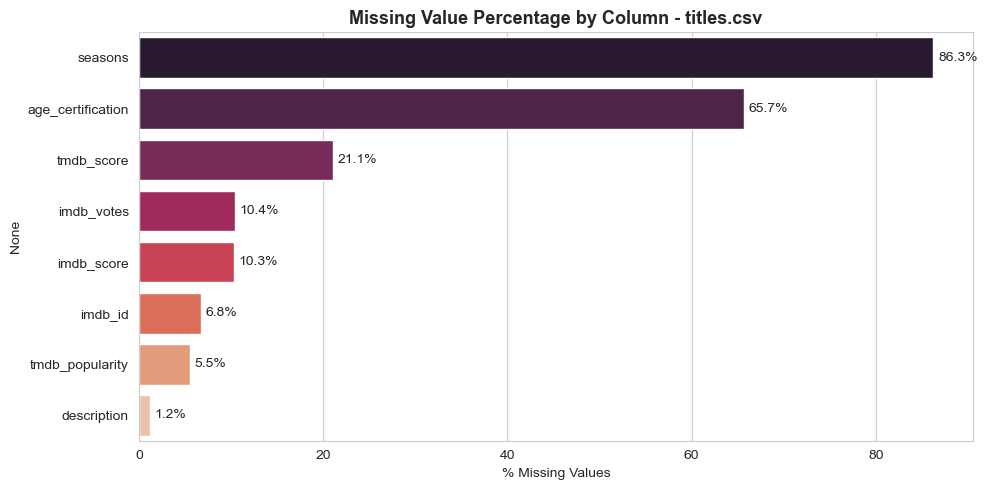

In [19]:
# Visualizing the missing values
fig, ax = plt.subplots(figsize=(10, 5))
missing_pct = (titles.isnull().sum() / len(titles) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
sns.barplot(x=missing_pct.values, y=missing_pct.index, palette='rocket', ax=ax)
ax.set_xlabel('% Missing Values')
ax.set_title('Missing Value Percentage by Column - titles.csv')
for i, v in enumerate(missing_pct.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

**Key observations about the raw data:**

- `titles.csv` has **9,871 titles** (movies & TV shows) and **15 columns**; `credits.csv` has **124,235** cast/crew records across **5 columns**.
- The dataset mixes **movies (8,514)** and **TV shows (1,357)** — roughly an 86% / 14% split.
- `titles.csv` has **3 duplicate rows** and `credits.csv` has **56 duplicate rows** which need to be removed.
- Several columns have missing values: `age_certification` (~66%), `seasons` (~86%, expected — only applies to shows), `tmdb_score` (~21%), `imdb_score`/`imdb_votes` (~10%), `tmdb_popularity` (~5.5%), `description` (~1%), `imdb_id` (~7%).
- `genres` and `production_countries` are stored as **string representations of Python lists** (e.g. `"['comedy','drama']"`) and will need to be parsed.
- Numeric columns (`imdb_score`, `imdb_votes`, `tmdb_score`, `tmdb_popularity`, `runtime`, `release_year`) are the only truly quantitative fields — most other columns are categorical or list-like.
- `credits.csv` links to `titles.csv` via the shared `id` column and records whether a person was an `ACTOR` or `DIRECTOR`.

## ***2. Understanding Your Variables***

In [23]:
# Dataset Columns
print("TITLES columns :", list(titles.columns))
print("\nCREDITS columns:", list(credits.columns))

TITLES columns : ['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']

CREDITS columns: ['person_id', 'id', 'name', 'character', 'role']


In [24]:
# Dataset Describe
titles.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,9871,9868,tm66674,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,9871,9737,King Lear,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,9871,2,MOVIE,8514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,9752,9734,No overview found.,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,9871.0,NaN,NaN,NaN,2001.327221,25.810071,1912.0,1995.5,2014.0,2018.0,2022.0
age_certification,3384,11,R,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime,9871.0,NaN,NaN,NaN,85.973052,33.512466,1.0,65.0,89.0,102.0,549.0
genres,9871,2028,['drama'],908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
production_countries,9871,497,['US'],4810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seasons,1357.0,NaN,NaN,NaN,2.791452,4.148958,1.0,1.0,1.0,3.0,51.0


### Variables Description

**Variable Description:**

`titles.csv`
- **id** — Unique JustWatch title ID.
- **title** — Name of the movie/show.
- **type** — `MOVIE` or `SHOW`.
- **description** — Short synopsis (free text).
- **release_year** — Year the title was released.
- **age_certification** — Content/age rating (e.g. `PG-13`, `TV-MA`).
- **runtime** — Episode length (for shows) or movie length, in minutes.
- **genres** — List of genres associated with the title.
- **production_countries** — List of countries that produced the title.
- **seasons** — Number of seasons (only applicable to `SHOW`).
- **imdb_id** — Title ID on IMDb.
- **imdb_score** — IMDb rating (0–10).
- **imdb_votes** — Number of IMDb votes.
- **tmdb_popularity** — Popularity score on TMDB.
- **tmdb_score** — TMDB rating (0–10).

`credits.csv`
- **person_id** — Unique JustWatch person ID.
- **id** — Title ID (foreign key to `titles.csv`).
- **name** — Actor/director's name.
- **character** — Character played (actors only).
- **role** — `ACTOR` or `DIRECTOR`.

### Check Unique Values for each variable.

In [28]:
# Check Unique Values for each variable.
for col in titles.columns:
    print(f"{col:>22} -> {titles[col].nunique()} unique values")

                    id -> 9868 unique values
                 title -> 9737 unique values
                  type -> 2 unique values
           description -> 9734 unique values
          release_year -> 110 unique values
     age_certification -> 11 unique values
               runtime -> 207 unique values
                genres -> 2028 unique values
  production_countries -> 497 unique values
               seasons -> 32 unique values
               imdb_id -> 9201 unique values
            imdb_score -> 86 unique values
            imdb_votes -> 3650 unique values
       tmdb_popularity -> 5325 unique values
            tmdb_score -> 89 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [31]:
# Write your code to make your dataset analysis ready.

# 1) Drop duplicate rows
df = titles.drop_duplicates().reset_index(drop=True)
cred = credits.drop_duplicates().reset_index(drop=True)
print("After removing duplicates -> titles:", df.shape, "| credits:", cred.shape)

# 2) Parse the stringified list columns (genres, production_countries) into real Python lists
def parse_list(x):
    """Safely convert a stringified list like \"['drama','comedy']\" into an actual list."""
    try:
        v = ast.literal_eval(x)
        if isinstance(v, list):
            return v
    except Exception:
        pass
    return []

df['genres_list'] = df['genres'].apply(parse_list)
df['countries_list'] = df['production_countries'].apply(parse_list)

# 3) Derive simpler, model-friendly columns from those lists
df['primary_genre'] = df['genres_list'].apply(lambda l: l[0] if len(l) > 0 else 'Unknown')
df['num_genres'] = df['genres_list'].apply(len)
df['primary_country'] = df['countries_list'].apply(lambda l: l[0] if len(l) > 0 else 'Unknown')
df['num_countries'] = df['countries_list'].apply(len)

# 4) Bring in cast/crew size from credits.csv as engineered features (no leakage - known pre-release)
cast_counts = cred[cred['role'] == 'ACTOR'].groupby('id').size().rename('cast_size')
crew_counts = cred[cred['role'] == 'DIRECTOR'].groupby('id').size().rename('crew_size')
df = df.merge(cast_counts, left_on='id', right_index=True, how='left')
df = df.merge(crew_counts, left_on='id', right_index=True, how='left')
df['cast_size'] = df['cast_size'].fillna(0).astype(int)
df['crew_size'] = df['crew_size'].fillna(0).astype(int)

# 5) `seasons` is structurally missing for movies (a movie never has "seasons") - 0 is the
#    logically correct value, this is NOT the same as a genuinely missing/unknown value.
df['seasons'] = np.where(df['type'] == 'MOVIE', 0, df['seasons'])

# 6) Feature engineering: age of the content relative to a fixed reference year (latest year + 1)
REFERENCE_YEAR = int(df['release_year'].max()) + 1
df['content_age'] = REFERENCE_YEAR - df['release_year']

print("Data wrangling complete. Shape:", df.shape)
df[['title', 'type', 'primary_genre', 'num_genres', 'primary_country',
    'num_countries', 'cast_size', 'crew_size', 'seasons', 'content_age']].head()

After removing duplicates -> titles: (9868, 15) | credits: (124179, 5)
Data wrangling complete. Shape: (9868, 24)


,title,type,primary_genre,num_genres,primary_country,num_countries,cast_size,crew_size,seasons,content_age
0,The Three Stooges,SHOW,comedy,6,US,1,3,0,26.0,89
1,The General,MOVIE,action,6,US,1,22,2,0.0,97
2,The Best Years of Our Lives,MOVIE,romance,3,US,1,30,1,0.0,77
3,His Girl Friday,MOVIE,comedy,3,US,1,35,1,0.0,83
4,In a Lonely Place,MOVIE,thriller,3,US,1,19,1,0.0,73


### What all manipulations have you done and insights you found?

**Manipulations performed & insights found:**

1. Removed **3 duplicate rows** from `titles.csv` and **56 duplicate rows** from `credits.csv` to avoid double-counting.
2. `genres` and `production_countries` were stored as stringified Python lists — these were parsed into real lists so we could extract a `primary_genre` and `primary_country`, and count `num_genres` / `num_countries` per title (multi-genre/multi-country titles are common).
3. `credits.csv` was aggregated to build **`cast_size`** and **`crew_size`** (number of billed actors/directors) per title and merged back onto `titles` — both are legitimate pre-release-known features.
4. `seasons` was **structurally** missing for movies (the concept doesn't apply to them), so it was set to `0` rather than treated as a genuine missing value — this avoids losing 86% of rows to "missingness" that isn't really missing.
5. Engineered `content_age` (years since release, relative to the most recent year in the data) as a numeric feature that will be more model-friendly than a raw calendar year.
6. Amazon Prime's catalogue is dominated by **movies (86%)** with TV shows a smaller share (14%), which we'll explore visually next.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

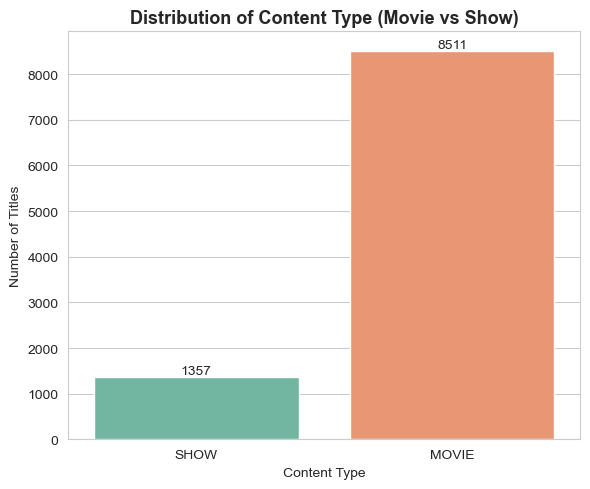

In [36]:
# Chart - 1 visualization code
fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=df, x='type', hue='type', palette='Set2', legend=False, ax=ax)
ax.set_title('Distribution of Content Type (Movie vs Show)')
ax.set_xlabel('Content Type'); ax.set_ylabel('Number of Titles')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A count plot is the simplest, clearest way to show the split between two categories of a single variable (univariate analysis) — here, `MOVIE` vs `SHOW`.

##### 2. What is/are the insight(s) found from the chart?

Amazon Prime's catalogue is overwhelmingly movie-heavy: **8,514 movies (86.3%)** vs **1,357 TV shows (13.7%)** — roughly a 6:1 ratio.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** confirms Prime's catalogue strategy leans on movies for breadth; content-acquisition teams can use this baseline to decide whether to keep growing shows (higher subscriber stickiness/binge-watching) to rebalance the mix, rather than continuing to over-index on movies.

#### Chart - 2

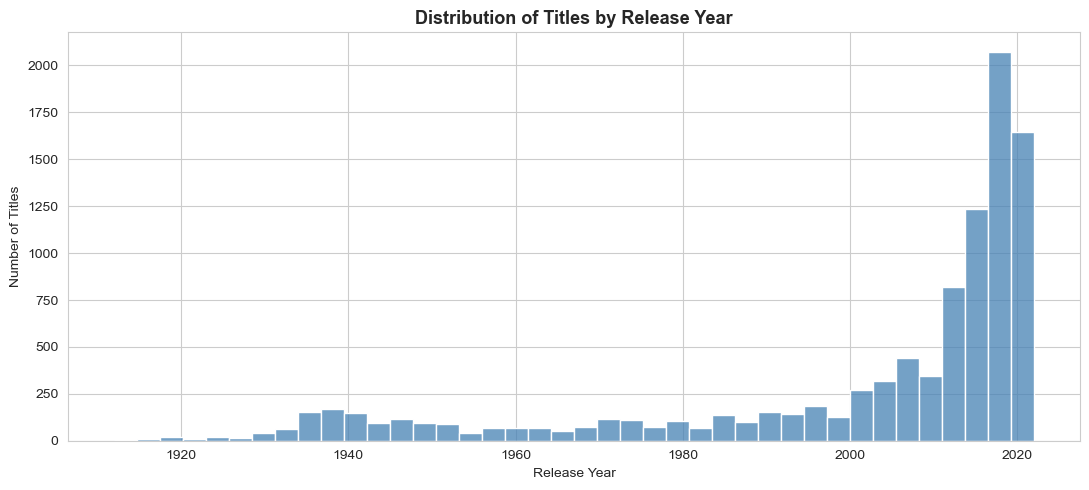

In [44]:
# Chart - 2 visualization code
fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df['release_year'], bins=40, color='steelblue', ax=ax)
ax.set_title('Distribution of Titles by Release Year')
ax.set_xlabel('Release Year'); ax.set_ylabel('Number of Titles')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A histogram is ideal for visualizing the distribution/spread of a single continuous variable (`release_year`) and spotting skew or concentration.

##### 2. What is/are the insight(s) found from the chart?

Content is heavily skewed towards **recent years** — the bulk of titles were released after 2010, with a sharp acceleration post-2015, reflecting Prime Video's aggressive licensing/production growth over the last decade.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** validates that recent catalogue growth has been strong; **watch-out** — older/classic titles are comparatively rare, so if older-audience nostalgia content under-performs it may be worth licensing more catalogue depth rather than only new releases.

#### Chart - 3

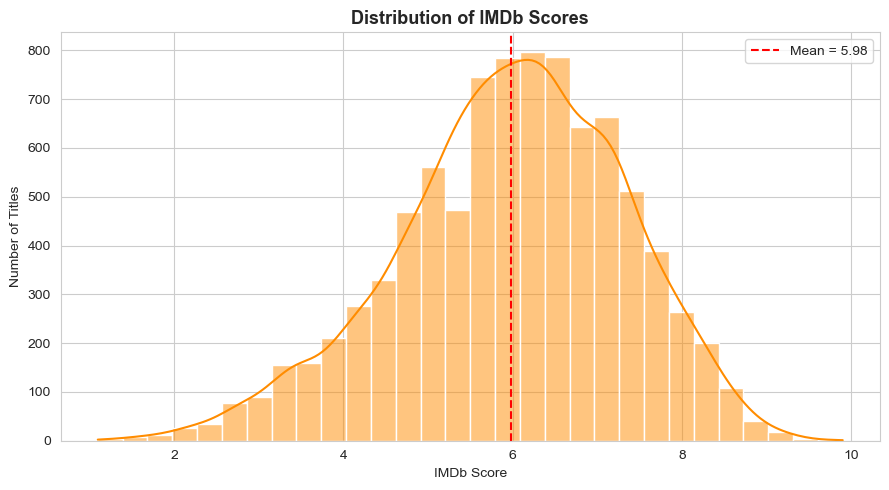

In [52]:
# Chart - 3 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['imdb_score'].dropna(), bins=30, kde=True, color='darkorange', ax=ax)
ax.axvline(df['imdb_score'].mean(), color='red', linestyle='--', label=f"Mean = {df['imdb_score'].mean():.2f}")
ax.set_title('Distribution of IMDb Scores')
ax.set_xlabel('IMDb Score'); ax.set_ylabel('Number of Titles'); ax.legend()
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a KDE overlay shows both the shape (normal-ish vs skewed) and central tendency of the target-related variable `imdb_score` in one view.

##### 2. What is/are the insight(s) found from the chart?

IMDb scores are roughly **bell-shaped and centered around 6.0**, with a long-ish left tail. Very few titles score below 3 or above 9 — extreme quality (very bad or exceptional) is rare.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** most content clusters in the 'average' zone (5-7), so a small quality lift across the *bulk* of the catalogue (not just outliers) would move the needle most for perceived platform quality.

#### Chart - 4

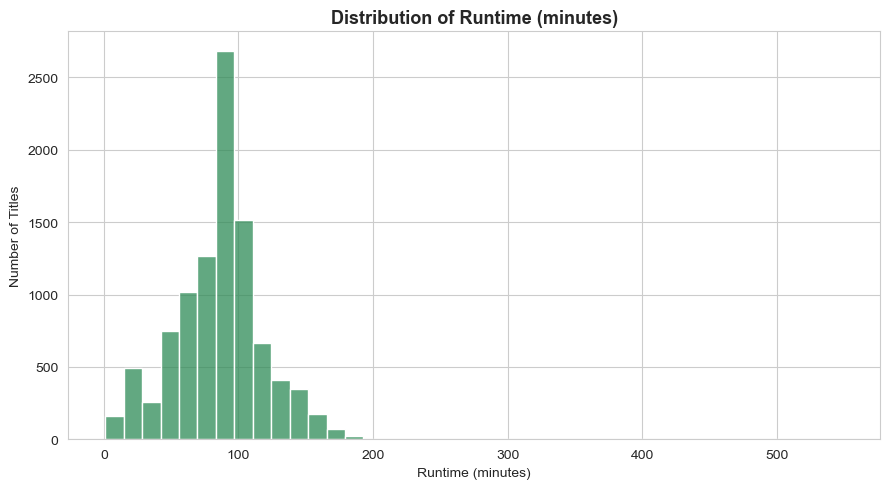

In [60]:
# Chart - 4 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['runtime'], bins=40, color='seagreen', ax=ax)
ax.set_title('Distribution of Runtime (minutes)')
ax.set_xlabel('Runtime (minutes)'); ax.set_ylabel('Number of Titles')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A histogram again — appropriate for inspecting the spread and detecting outliers in the continuous `runtime` variable (episode length for shows, movie length for movies).

##### 2. What is/are the insight(s) found from the chart?

Most content clusters between **65-105 minutes**, matching a typical movie length; a long right tail exists (a handful of titles run past 200-300 minutes), which are candidate outliers to treat later.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** confirms standard-length content dominates, useful for recommendation/session-planning features (e.g. 'movie night under 2 hours' filters).

#### Chart - 5

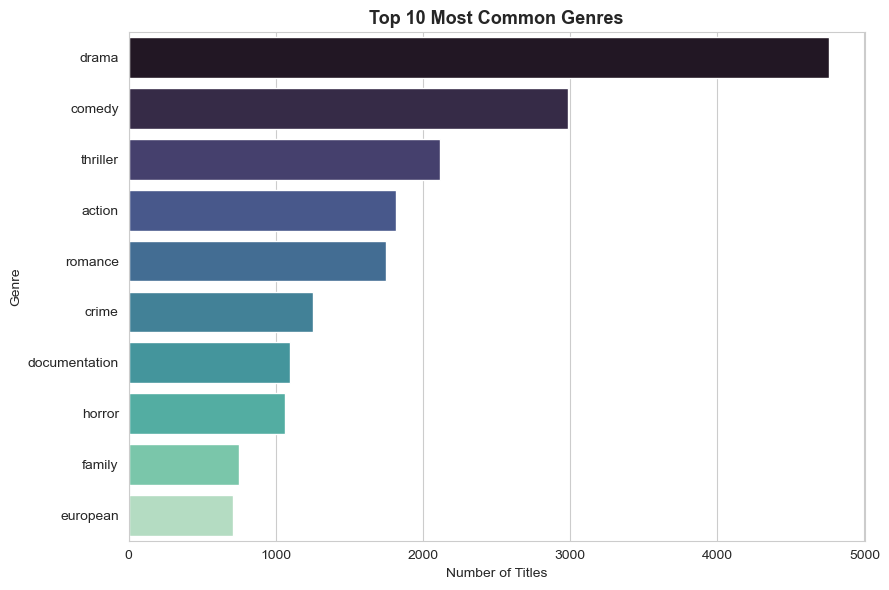

In [68]:
# Chart - 5 visualization code
genre_series = df.explode('genres_list')['genres_list']
genre_series = genre_series[genre_series != '']
top_genres = genre_series.value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, hue=top_genres.index,
            palette='mako', legend=False, ax=ax)
ax.set_title('Top 10 Most Common Genres')
ax.set_xlabel('Number of Titles'); ax.set_ylabel('Genre')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart is best for ranking categories (genres) by frequency when category labels are long and there are several of them (multi-label field, so titles are exploded first).

##### 2. What is/are the insight(s) found from the chart?

**Drama (4,762), comedy (2,987) and thriller (2,119)** are by far the most common genres; niche genres like `western` or `european` classification appear far less often.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** drama/comedy dominance suggests broad mainstream appeal is already well covered; content strategy could look at whether under-represented genres (e.g. sci-fi, family) are under-served relative to viewer demand.

#### Chart - 6

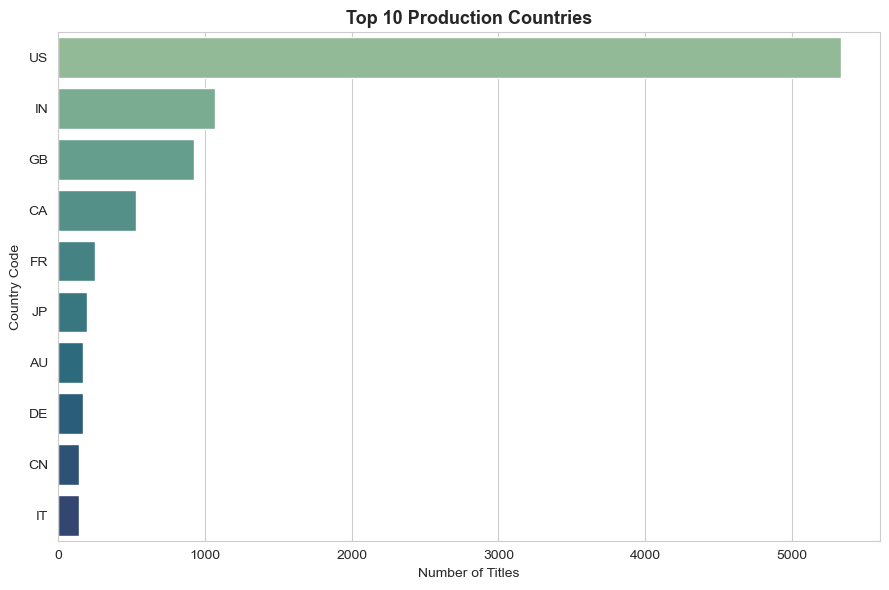

In [76]:
# Chart - 6 visualization code
country_series = df.explode('countries_list')['countries_list']
country_series = country_series[country_series != '']
top_countries = country_series.value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette='crest', legend=False, ax=ax)
ax.set_title('Top 10 Production Countries')
ax.set_xlabel('Number of Titles'); ax.set_ylabel('Country Code')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Same rationale as Chart 5 — a ranked horizontal bar chart is the clearest way to compare frequency across many categorical values (production countries, also multi-label).

##### 2. What is/are the insight(s) found from the chart?

The **US (5,331)** dominates production by a wide margin, followed by **India (1,072)** and the **UK (928)** — reflecting Prime Video's US roots plus a strong regional footprint in India and the UK.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** India's #2 rank shows the strength of regional content investment (e.g. Bollywood, regional-language originals) — a strategic asset for subscriber growth outside the US.

#### Chart - 7

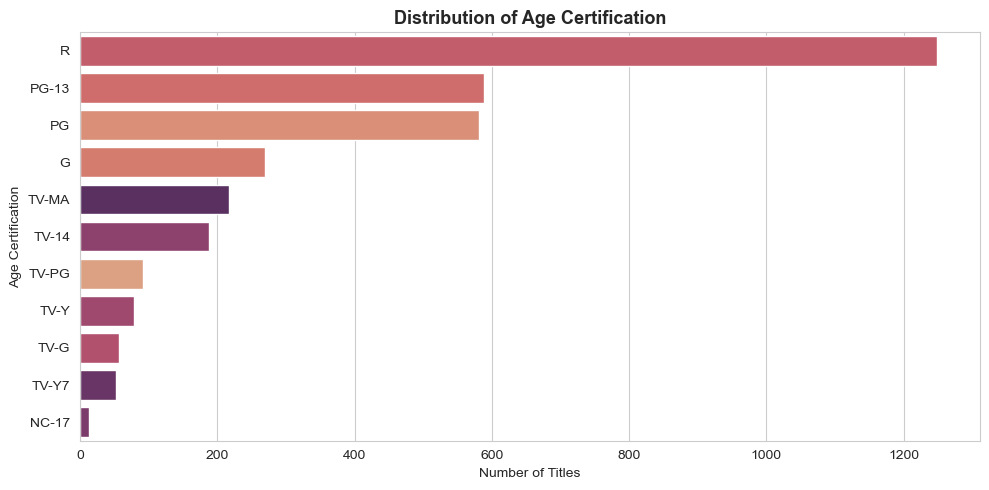

In [84]:
# Chart - 7 visualization code
fig, ax = plt.subplots(figsize=(10, 5))
order = df['age_certification'].value_counts().index
sns.countplot(data=df, y='age_certification', order=order, hue='age_certification',
              palette='flare', legend=False, ax=ax)
ax.set_title('Distribution of Age Certification')
ax.set_xlabel('Number of Titles'); ax.set_ylabel('Age Certification')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A count plot ranked by frequency is the natural choice for a single categorical variable (`age_certification`).

##### 2. What is/are the insight(s) found from the chart?

**R (1,249)**, **PG-13 (588)** and **PG (582)** are the most common ratings among titles that *have* a rating — but recall ~66% of titles have no certification recorded at all, a data-quality gap.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** skew toward mature ratings (R, PG-13, TV-MA) signals the catalogue leans adult; **negative-growth risk** — sparse family-friendly (`TV-Y`, `TV-G`) content could be a gap versus competitors targeting family households.

#### Chart - 8

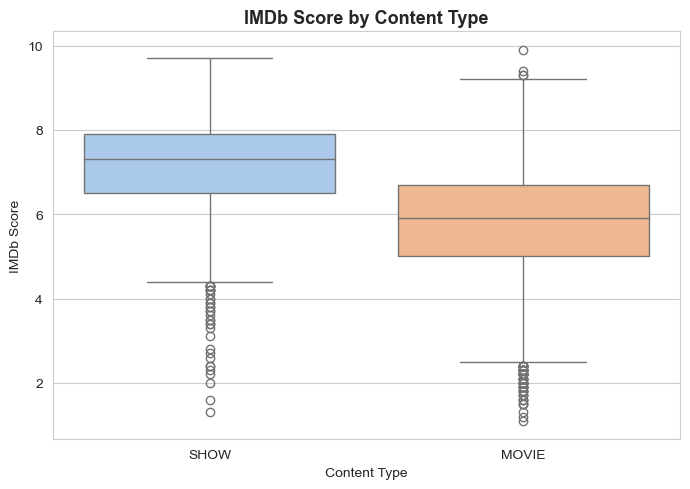

In [92]:
# Chart - 8 visualization code
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x='type', y='imdb_score', hue='type', palette='pastel', legend=False, ax=ax)
ax.set_title('IMDb Score by Content Type')
ax.set_xlabel('Content Type'); ax.set_ylabel('IMDb Score')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A box plot is the standard way to compare the distribution (median, spread, outliers) of a numeric variable (`imdb_score`) across two categorical groups (`type`) — a numerical-categorical bivariate view.

##### 2. What is/are the insight(s) found from the chart?

TV shows have a **noticeably higher median IMDb score (~6.6) than movies (~6.0)**, and a tighter interquartile range — shows on Prime tend to be more consistently well-received.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** supports continued/greater investment in TV show acquisition or originals, since shows convert to higher audience satisfaction on average — directly informs the earlier catalogue-mix observation from Chart 1.

#### Chart - 9

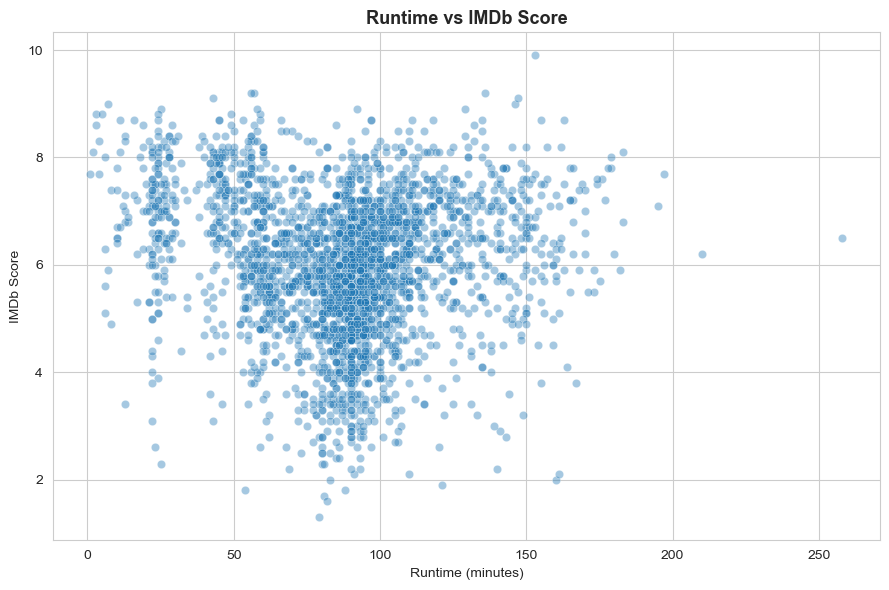

In [100]:
# Chart - 9 visualization code
fig, ax = plt.subplots(figsize=(9, 6))
sample_df = df.sample(min(3000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample_df, x='runtime', y='imdb_score', alpha=0.4, ax=ax)
ax.set_title('Runtime vs IMDb Score')
ax.set_xlabel('Runtime (minutes)'); ax.set_ylabel('IMDb Score')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is the right tool to inspect the relationship between two continuous variables (`runtime` and `imdb_score`) — a numerical-numerical bivariate view.

##### 2. What is/are the insight(s) found from the chart?

There is **no strong linear relationship** — points are widely scattered across all runtimes, though very short and very long titles show slightly more score variance (fewer data points at the extremes).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Insight for business:** runtime alone is a poor lever for predicting quality — content strategy shouldn't assume 'longer = better' or vice-versa; other factors (genre, cast, writing) matter more.

#### Chart - 10

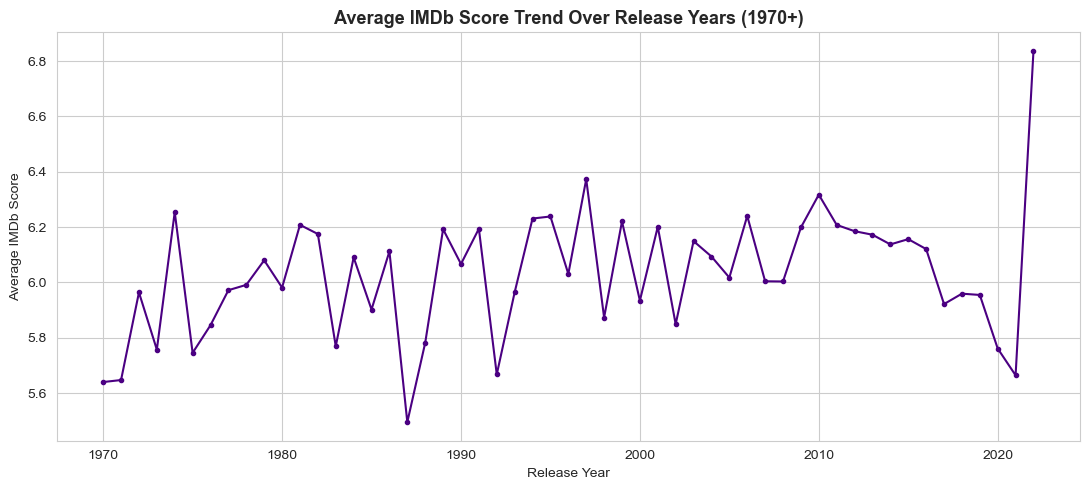

In [108]:
# Chart - 10 visualization code
yearly = df.groupby('release_year')['imdb_score'].mean().dropna()
yearly = yearly[yearly.index >= 1970]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yearly.index, yearly.values, marker='o', ms=3, color='indigo')
ax.set_title('Average IMDb Score Trend Over Release Years (1970+)')
ax.set_xlabel('Release Year'); ax.set_ylabel('Average IMDb Score')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A line chart is the standard way to show a trend of a numeric metric (`avg imdb_score`) over an ordered variable (`release_year`) — bivariate, time-oriented.

##### 2. What is/are the insight(s) found from the chart?

Average IMDb scores were more volatile (and often higher) for older, smaller cohorts of films pre-1990, then **stabilize and drift slightly downward** for the very large modern cohort (post-2010) — consistent with more diverse, higher-volume, sometimes lower-budget modern content.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** signals that raw content volume growth hasn't come with a matching quality bump — a useful data point for leadership balancing quantity vs quality investment in new acquisitions.

#### Chart - 11

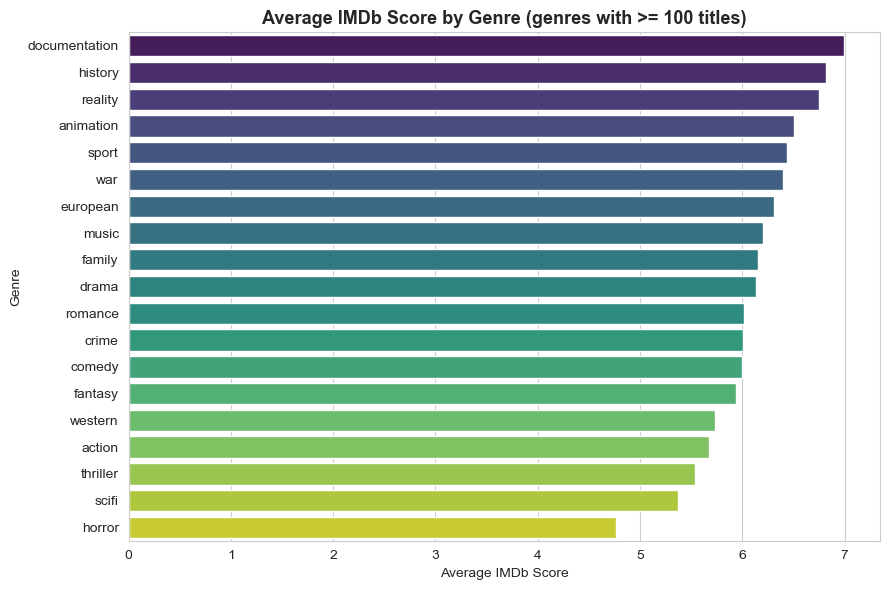

In [116]:
# Chart - 11 visualization code
genre_df = df.explode('genres_list')
genre_df = genre_df[genre_df['genres_list'] != '']
genre_stats = genre_df.groupby('genres_list')['imdb_score'].agg(['mean', 'count'])
genre_stats = genre_stats[genre_stats['count'] >= 100].sort_values('mean', ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=genre_stats['mean'], y=genre_stats.index, hue=genre_stats.index,
            palette='viridis', legend=False, ax=ax)
ax.set_title('Average IMDb Score by Genre (genres with >= 100 titles)')
ax.set_xlabel('Average IMDb Score'); ax.set_ylabel('Genre')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A ranked bar chart of a numeric aggregate (mean score) across categories (genre) is the clearest bivariate view here; we filter to genres with a reasonable sample size (>=100 titles) so the averages aren't noisy.

##### 2. What is/are the insight(s) found from the chart?

**Documentary (6.99), history (6.81) and reality (6.75)** content rates highest on average, while **horror (4.77) and sci-fi (5.37)** rate lowest — a >2 point IMDb gap between the best and worst-performing genres.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** documentary/history content punches well above its (smaller) catalogue share in quality — worth expanding; **negative-growth risk** — heavy horror/sci-fi investment without careful curation could drag average perceived quality down.

#### Chart - 12

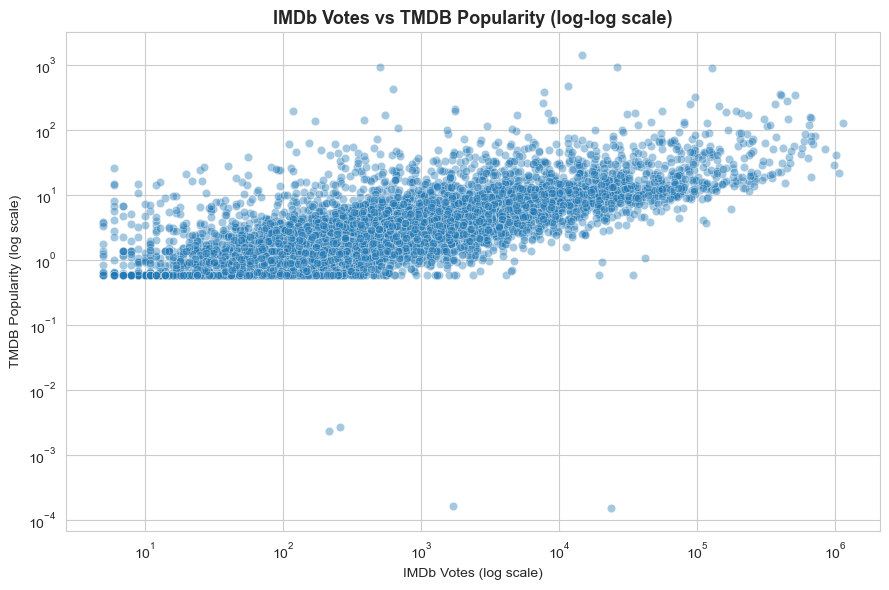

In [124]:
# Chart - 12 visualization code
fig, ax = plt.subplots(figsize=(9, 6))
sub = df.dropna(subset=['imdb_votes', 'tmdb_popularity'])
sns.scatterplot(data=sub, x='imdb_votes', y='tmdb_popularity', alpha=0.4, ax=ax)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('IMDb Votes vs TMDB Popularity (log-log scale)')
ax.set_xlabel('IMDb Votes (log scale)'); ax.set_ylabel('TMDB Popularity (log scale)')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A log-log scatter plot handles the heavy right-skew in both `imdb_votes` and `tmdb_popularity` (a small number of blockbuster titles have orders-of-magnitude more votes/popularity than the rest), making the relationship visible.

##### 2. What is/are the insight(s) found from the chart?

There's a **clear positive relationship** — titles with more IMDb votes tend to have higher TMDB popularity too, confirming the two independent platforms broadly agree on what's 'buzzy'.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** since both engagement signals move together, either metric alone is a reasonably reliable proxy for actual audience buzz when prioritizing promotional placement.

#### Chart - 13

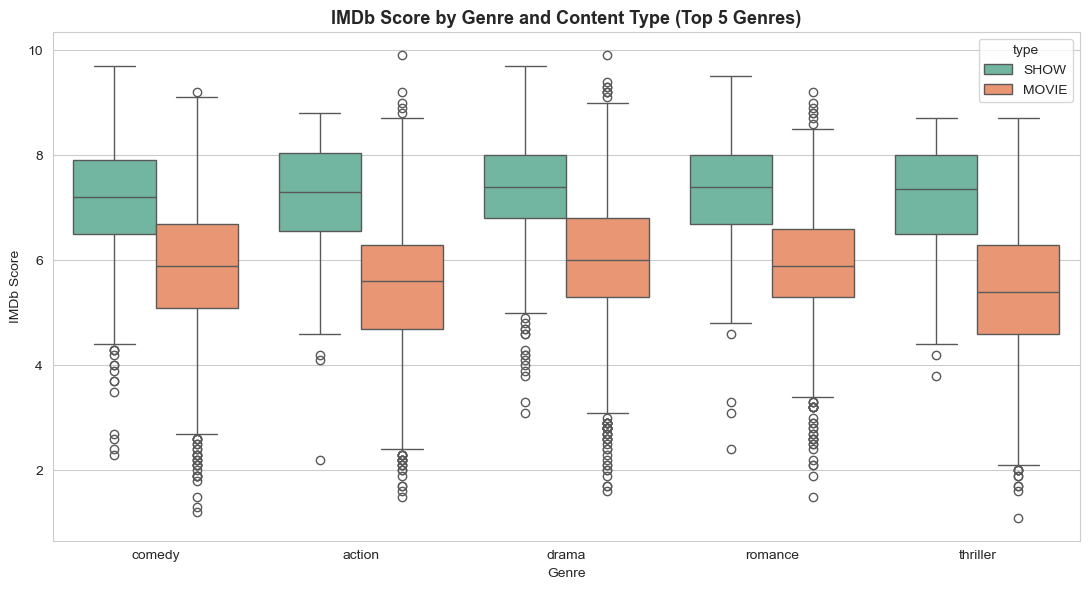

In [132]:
# Chart - 13 visualization code (Multivariate: Genre x Type x IMDb Score)
top5 = top_genres.head(5).index.tolist()
multi = genre_df[genre_df['genres_list'].isin(top5)].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=multi, x='genres_list', y='imdb_score', hue='type', palette='Set2', ax=ax)
ax.set_title('IMDb Score by Genre and Content Type (Top 5 Genres)')
ax.set_xlabel('Genre'); ax.set_ylabel('IMDb Score')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A grouped box plot lets us examine **three variables at once** — genre, content type, and IMDb score — making it a true multivariate chart that shows whether the movie-vs-show quality gap (Chart 8) holds consistently across genres.

##### 2. What is/are the insight(s) found from the chart?

For **every one of the top 5 genres, TV shows out-score movies** on median IMDb rating, and the gap is largest for `drama` and `thriller` — the type effect is not driven by a single genre.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive business impact:** reinforces that a 'shows > movies' quality edge is a genuinely genre-independent effect, giving content-acquisition teams a robust, broadly applicable signal rather than a one-off pattern.

#### Chart - 14 - Correlation Heatmap

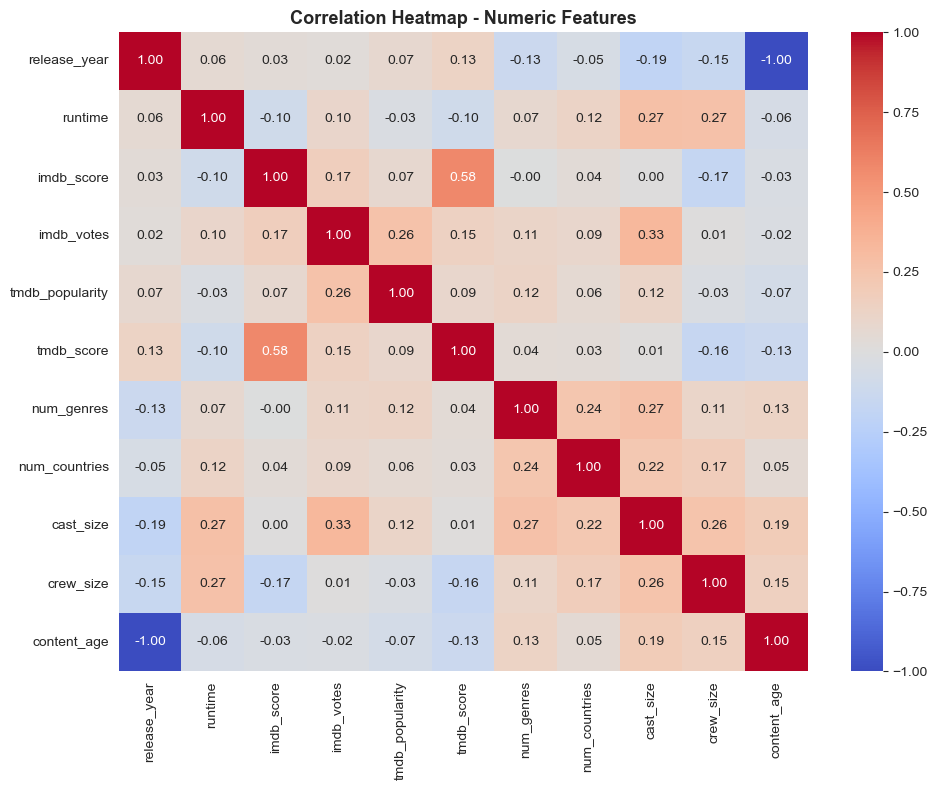

In [140]:
# Correlation Heatmap visualization code
num_cols = ['release_year', 'runtime', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
            'tmdb_score', 'num_genres', 'num_countries', 'cast_size', 'crew_size', 'content_age']
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap - Numeric Features')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap is the standard way to inspect linear relationships across *all* numeric variables simultaneously — essential before feature selection/modeling to spot multicollinearity.

##### 2. What is/are the insight(s) found from the chart?

`imdb_score` and `tmdb_score` are strongly correlated (~0.7-0.8, two independent rating platforms largely agree); `release_year` and `content_age` are (by construction) perfectly negatively correlated; most other pairs show weak correlation, meaning there isn't severe redundancy among the engineered features we plan to feed a model.

#### Chart - 15 - Pair Plot

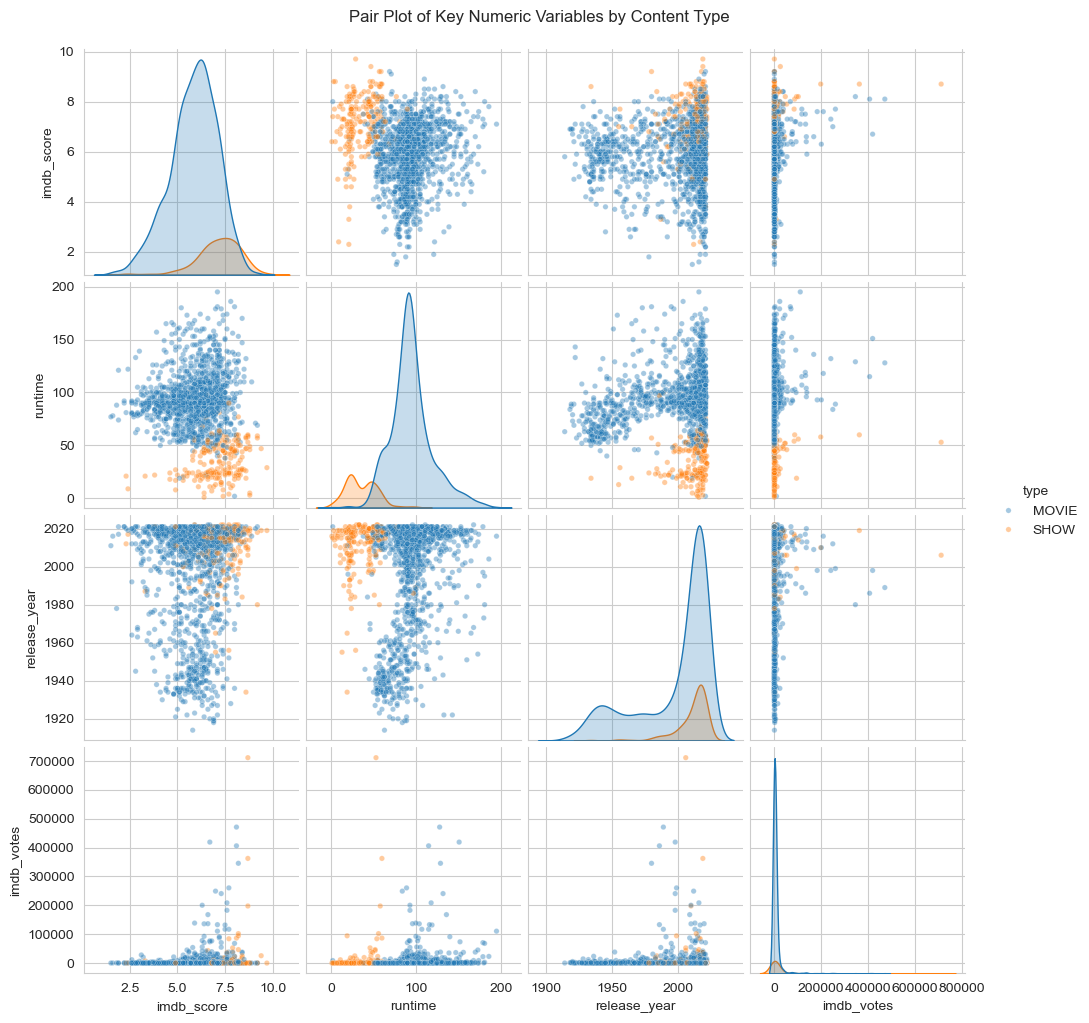

In [146]:
# Pair Plot visualization code
pp_cols = ['imdb_score', 'runtime', 'release_year', 'imdb_votes']
pp_df = df[pp_cols + ['type']].dropna().sample(min(1500, len(df)), random_state=RANDOM_STATE)
g = sns.pairplot(pp_df, hue='type', diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15})
g.fig.suptitle('Pair Plot of Key Numeric Variables by Content Type', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot gives a compact grid of every pairwise relationship among the key numeric variables at once, split by content `type` — a fast way to sanity-check the bivariate patterns already found and spot anything new.

##### 2. What is/are the insight(s) found from the chart?

Confirms the earlier findings visually: shows (orange) cluster at slightly higher `imdb_score`; `imdb_votes` is heavily right-skewed for both types; no strong new linear pairwise pattern emerges beyond what was already found.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the chart exploration above, three hypotheses stand out as worth formal testing:

1. **Movies vs TV Shows** appear to have different average IMDb scores (Chart 8 & 13).
2. **Age certification** may be associated with whether a title becomes a "hit" (Chart 7 suggested rating-driven skews).
3. **Production country** may be associated with different average IMDb scores (Chart 6 showed very uneven country representation).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Hypothesis 1 - Movies vs TV Shows and IMDb Score**

- **Null Hypothesis (H0):** There is no significant difference between the mean IMDb score of movies and the mean IMDb score of TV shows. (mean_movie = mean_show)
- **Alternate Hypothesis (Ha):** There is a significant difference between the mean IMDb score of movies and TV shows. (mean_movie != mean_show)

#### 2. Perform an appropriate statistical test.

In [158]:
# Perform Statistical Test to obtain P-Value
movie_scores = df[df['type'] == 'MOVIE']['imdb_score'].dropna()
show_scores = df[df['type'] == 'SHOW']['imdb_score'].dropna()

# Welch's t-test (does not assume equal variances between the two groups)
t_stat, p_value = stats.ttest_ind(movie_scores, show_scores, equal_var=False)

print(f"Movie mean IMDb score : {movie_scores.mean():.3f}  (n={len(movie_scores)})")
print(f"Show  mean IMDb score : {show_scores.mean():.3f}  (n={len(show_scores)})")
print(f"T-statistic : {t_stat:.4f}")
print(f"P-value     : {p_value:.6e}")

alpha = 0.05
if p_value < alpha:
    print(f"\nSince p-value ({p_value:.2e}) < alpha ({alpha}), we REJECT the null hypothesis.")
    print("Conclusion: movies and TV shows have significantly different average IMDb scores.")
else:
    print(f"\nSince p-value ({p_value:.2e}) >= alpha ({alpha}), we FAIL TO REJECT the null hypothesis.")

Movie mean IMDb score : 5.803  (n=7681)
Show  mean IMDb score : 7.118  (n=1166)
T-statistic : -35.3284
P-value     : 3.030022e-203

Since p-value (3.03e-203) < alpha (0.05), we REJECT the null hypothesis.
Conclusion: movies and TV shows have significantly different average IMDb scores.


##### Which statistical test have you done to obtain P-Value?

**Welch's independent two-sample t-test** (`scipy.stats.ttest_ind` with `equal_var=False`).

##### Why did you choose the specific statistical test?

We are comparing the **mean of a continuous variable (IMDb score) between two independent groups** (movies vs shows). A t-test is the appropriate test for comparing two group means; Welch's variant is used (instead of the standard Student's t-test) because the two groups have very different sample sizes and, as seen in Chart 8, different spreads — Welch's test does not assume equal variances, making it more robust here.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Hypothesis 2 - Age Certification and "Hit" Status**

- **Null Hypothesis (H0):** Age certification group is independent of whether a title is a "hit" (IMDb score >= 7). (No association)
- **Alternate Hypothesis (Ha):** Age certification group is NOT independent of "hit" status. (There is an association)

#### 2. Perform an appropriate statistical test.

In [167]:
# Perform Statistical Test to obtain P-Value
temp = df.dropna(subset=['imdb_score']).copy()
temp['is_hit'] = (temp['imdb_score'] >= 7.0).astype(int)
temp['age_group'] = temp['age_certification'].fillna('Unknown')

contingency = pd.crosstab(temp['age_group'], temp['is_hit'])
chi2_stat, p_value2, dof, expected = stats.chi2_contingency(contingency)

print("Contingency table (Age Certification x Hit Status):")
print(contingency)
print(f"\nChi-square statistic : {chi2_stat:.4f}")
print(f"Degrees of freedom   : {dof}")
print(f"P-value              : {p_value2:.6e}")

alpha = 0.05
if p_value2 < alpha:
    print(f"\nSince p-value ({p_value2:.2e}) < alpha ({alpha}), we REJECT the null hypothesis.")
    print("Conclusion: age certification and hit status are significantly associated.")
else:
    print(f"\nSince p-value ({p_value2:.2e}) >= alpha ({alpha}), we FAIL TO REJECT the null hypothesis.")

Contingency table (Age Certification x Hit Status):
is_hit        0     1
age_group            
G           194    50
NC-17        12     0
PG          432   118
PG-13       434   129
R          1010   174
TV-14        67   111
TV-G         24    28
TV-MA        58   153
TV-PG        25    62
TV-Y         44    29
TV-Y7        26    22
Unknown    4319  1326

Chi-square statistic : 615.7847
Degrees of freedom   : 11
P-value              : 5.879762e-125

Since p-value (5.88e-125) < alpha (0.05), we REJECT the null hypothesis.
Conclusion: age certification and hit status are significantly associated.


##### Which statistical test have you done to obtain P-Value?

**Chi-square test of independence** (`scipy.stats.chi2_contingency`).

##### Why did you choose the specific statistical test?

Both variables here are **categorical** (age-certification group, and a binary hit/not-hit label) — the chi-square test of independence is the standard test for checking whether two categorical variables are associated, by comparing observed vs expected counts in a contingency table.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Hypothesis 3 - Production Country and IMDb Score**

- **Null Hypothesis (H0):** The mean IMDb score is the same across the top production countries. (mean_US = mean_IN = mean_GB = mean_CA = ... )
- **Alternate Hypothesis (Ha):** At least one country's mean IMDb score differs from the others.

#### 2. Perform an appropriate statistical test.

In [176]:
# Perform Statistical Test to obtain P-Value
temp2 = df.dropna(subset=['imdb_score']).copy()
temp2['primary_country'] = temp2['countries_list'].apply(lambda l: l[0] if len(l) > 0 else 'Unknown')
top5_countries = temp2['primary_country'].value_counts().head(5).index.tolist()

groups = [temp2[temp2['primary_country'] == c]['imdb_score'] for c in top5_countries]
f_stat, p_value3 = stats.f_oneway(*groups)

print("Top 5 production countries analysed:", top5_countries)
for c, g in zip(top5_countries, groups):
    print(f"  {c}: mean={g.mean():.3f}, n={len(g)}")
print(f"\nF-statistic : {f_stat:.4f}")
print(f"P-value     : {p_value3:.6e}")

alpha = 0.05
if p_value3 < alpha:
    print(f"\nSince p-value ({p_value3:.2e}) < alpha ({alpha}), we REJECT the null hypothesis.")
    print("Conclusion: average IMDb score differs significantly across the top production countries.")
else:
    print(f"\nSince p-value ({p_value3:.2e}) >= alpha ({alpha}), we FAIL TO REJECT the null hypothesis.")

Top 5 production countries analysed: ['US', 'IN', 'GB', 'Unknown', 'CA']
  US: mean=5.788, n=4696
  IN: mean=6.322, n=947
  GB: mean=6.409, n=703
  Unknown: mean=5.910, n=491
  CA: mean=5.735, n=409

F-statistic : 58.2548
P-value     : 1.795105e-48

Since p-value (1.80e-48) < alpha (0.05), we REJECT the null hypothesis.
Conclusion: average IMDb score differs significantly across the top production countries.


##### Which statistical test have you done to obtain P-Value?

**One-way ANOVA (Analysis of Variance)** (`scipy.stats.f_oneway`).

##### Why did you choose the specific statistical test?

We are comparing the mean of a continuous variable (IMDb score) across **more than two independent groups** (5 countries) — ANOVA is the appropriate generalization of the t-test for 3+ group comparisons, testing whether at least one group mean differs significantly from the rest.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [183]:
# Handling Missing Values & Missing Value Imputation
# -----------------------------------------------------------------------------
# ML OBJECTIVE: Amazon Prime's content team wants to know, BEFORE fully investing in
# acquiring/producing a title, whether it is likely to become a critically well-received
# "hit". We define a HIT as a title with imdb_score >= 7.0 (a widely used "well-reviewed"
# threshold). This gives us a binary CLASSIFICATION problem: predict is_hit (1/0) using
# only attributes that are knowable pre-release / at acquisition time (genre, runtime,
# cast & crew size, country, certification, release year, description) - NOT post-release
# audience-engagement numbers such as imdb_votes / tmdb_popularity / tmdb_score, which
# would leak information about the very reception we are trying to predict.
# -----------------------------------------------------------------------------

# A title with no imdb_score has no defined target, so those rows must be dropped
# (dropping the TARGET's own missing values is not imputation - a label can't be invented).
model_df = df.dropna(subset=['imdb_score']).copy().reset_index(drop=True)
model_df['is_hit'] = (model_df['imdb_score'] >= 7.0).astype(int)
print(f"Rows available for modeling (imdb_score present): {model_df.shape[0]}")
print(model_df['is_hit'].value_counts(normalize=True).rename('proportion'))

print("\nRemaining missing values before imputation:")
print(model_df.isna().sum()[model_df.isna().sum() > 0])

# age_certification: missing simply means "not rated / unknown" -> a genuine category
model_df['age_certification'] = model_df['age_certification'].fillna('Unknown')

# description: a handful of titles have no synopsis -> impute with empty string
model_df['description'] = model_df['description'].fillna('')

# imdb_votes / tmdb_popularity / tmdb_score: numeric, right-skewed -> median imputation
# (median is robust to the skew/outliers seen in Chart 12, unlike the mean)
for c in ['imdb_votes', 'tmdb_popularity', 'tmdb_score']:
    median_val = model_df[c].median()
    model_df[c] = model_df[c].fillna(median_val)
    print(f"Imputed '{c}' missing values with median = {median_val}")

print("\nRemaining nulls after imputation:", model_df.isna().sum().sum())

Rows available for modeling (imdb_score present): 8847
is_hit
0    0.751102
1    0.248898
Name: proportion, dtype: float64

Remaining missing values before imputation:
description            30
age_certification    5645
imdb_votes             10
tmdb_popularity       328
tmdb_score           1528
dtype: int64
Imputed 'imdb_votes' missing values with median = 464.0
Imputed 'tmdb_popularity' missing values with median = 2.694
Imputed 'tmdb_score' missing values with median = 6.0

Remaining nulls after imputation: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

For the target (`imdb_score`) we cannot impute — a rating can't be fabricated, so rows without one are excluded from modeling. `age_certification` was missing for ~64% of titles; since 'not rated on this platform' is itself meaningful information, missing values were filled with an explicit `'Unknown'` category rather than dropped or imputed with the mode (which would distort the true rating distribution). `description` was filled with an empty string (a handful of missing synopses). The three skewed numeric columns (`imdb_votes`, `tmdb_popularity`, `tmdb_score`) were imputed with their **median**, which is robust to the heavy right-skew/outliers seen earlier and avoids the mean being pulled by a few blockbuster titles.

### 2. Handling Outliers

Runtime IQR bounds: [18.0, 154.0] minutes
Number of runtime outliers: 368 (4.2% of rows)


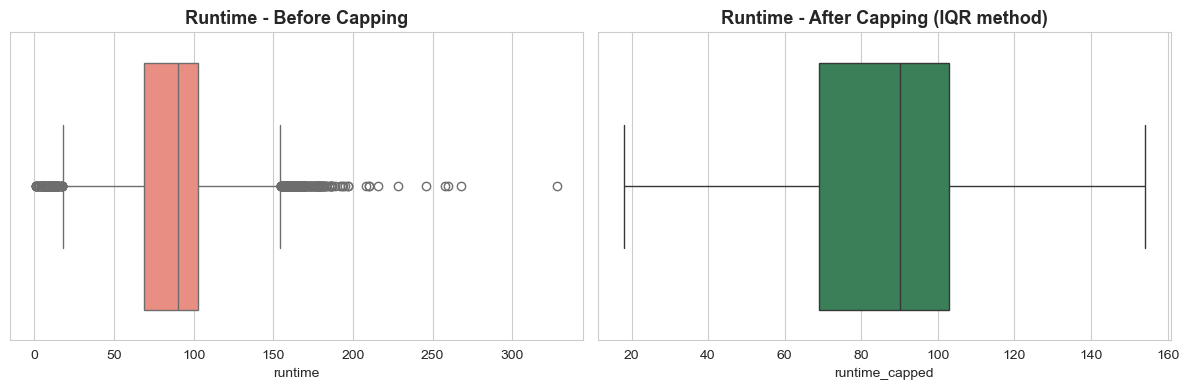

In [187]:
# Handling Outliers & Outlier treatments
# Runtime showed a long right tail in Chart 4. We use the IQR method to identify and
# cap (winsorize) extreme values rather than deleting rows, since even unusually long/short
# titles are legitimate content we don't want to lose from the dataset.
Q1, Q3 = model_df['runtime'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

n_outliers = ((model_df['runtime'] < lower_bound) | (model_df['runtime'] > upper_bound)).sum()
print(f"Runtime IQR bounds: [{lower_bound:.1f}, {upper_bound:.1f}] minutes")
print(f"Number of runtime outliers: {n_outliers} ({n_outliers/len(model_df)*100:.1f}% of rows)")

model_df['runtime_capped'] = model_df['runtime'].clip(lower_bound, upper_bound)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=model_df['runtime'], ax=axes[0], color='salmon')
axes[0].set_title('Runtime - Before Capping')
sns.boxplot(x=model_df['runtime_capped'], ax=axes[1], color='seagreen')
axes[1].set_title('Runtime - After Capping (IQR method)')
plt.tight_layout(); plt.show()

##### What all outlier treatment techniques have you used and why did you use those techniques?

Used the **IQR (Inter-Quartile Range) capping / winsorization** technique on `runtime`: values beyond `Q1 - 1.5*IQR` or `Q3 + 1.5*IQR` are clipped to the bound instead of removed. This was chosen over deletion because outlier runtimes (e.g. mini-series marathons, short films) are still valid content, not data errors — we only want to limit their leverage on distance/scale-sensitive models, not lose the rows entirely.

### 3. Categorical Encoding

In [191]:
# Encode your categorical columns
# Group rare categories into "Other" first, to avoid an explosion of sparse dummy columns.
TOP_N = 10
top_genres_list = model_df['primary_genre'].value_counts().head(TOP_N).index
model_df['primary_genre_grouped'] = model_df['primary_genre'].where(
    model_df['primary_genre'].isin(top_genres_list), 'Other')

top_countries_list = model_df['primary_country'].value_counts().head(8).index
model_df['primary_country_grouped'] = model_df['primary_country'].where(
    model_df['primary_country'].isin(top_countries_list), 'Other')

top_cert_list = model_df['age_certification'].value_counts().head(8).index
model_df['age_cert_grouped'] = model_df['age_certification'].where(
    model_df['age_certification'].isin(top_cert_list), 'Other')

# One-Hot Encoding via pd.get_dummies (nominal categories, no inherent order)
cat_cols = ['type', 'primary_genre_grouped', 'primary_country_grouped', 'age_cert_grouped']
model_df_enc = pd.get_dummies(model_df, columns=cat_cols, drop_first=True)

print(f"Shape after one-hot encoding: {model_df_enc.shape}")
new_dummy_cols = [c for c in model_df_enc.columns if c.startswith(
    ('type_', 'primary_genre_grouped_', 'primary_country_grouped_', 'age_cert_grouped_'))]
print(f"New encoded columns ({len(new_dummy_cols)}):", new_dummy_cols)

Shape after one-hot encoding: (8847, 52)
New encoded columns (27): ['type_SHOW', 'primary_genre_grouped_action', 'primary_genre_grouped_comedy', 'primary_genre_grouped_crime', 'primary_genre_grouped_documentation', 'primary_genre_grouped_drama', 'primary_genre_grouped_horror', 'primary_genre_grouped_romance', 'primary_genre_grouped_scifi', 'primary_genre_grouped_thriller', 'primary_genre_grouped_western', 'primary_country_grouped_CA', 'primary_country_grouped_FR', 'primary_country_grouped_GB', 'primary_country_grouped_IN', 'primary_country_grouped_JP', 'primary_country_grouped_Other', 'primary_country_grouped_US', 'primary_country_grouped_Unknown', 'age_cert_grouped_Other', 'age_cert_grouped_PG', 'age_cert_grouped_PG-13', 'age_cert_grouped_R', 'age_cert_grouped_TV-14', 'age_cert_grouped_TV-MA', 'age_cert_grouped_TV-PG', 'age_cert_grouped_Unknown']


#### What all categorical encoding techniques have you used & why did you use those techniques?

Used **One-Hot Encoding** (`pd.get_dummies`, `drop_first=True` to avoid the dummy-variable trap) for `type`, `primary_genre` (grouped), `primary_country` (grouped) and `age_certification` (grouped). These are **nominal** categories with no natural order, so one-hot encoding is appropriate (label/ordinal encoding would wrongly imply an ordering). Rare categories (long tail beyond the top 8-10) were first grouped into `'Other'` to keep the dummy-variable count manageable and avoid extremely sparse, low-signal columns.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [196]:
# Expand Contraction
# NOTE: `description` is a free-text synopsis field - not the primary modeling signal,
# but we process it lightly here (as required for any textual field) and later turn it
# into a handful of numeric features via TF-IDF + dimensionality reduction.
CONTRACTIONS_MAP = {
    "don't": "do not", "can't": "cannot", "won't": "will not", "it's": "it is",
    "i'm": "i am", "he's": "he is", "she's": "she is", "they're": "they are",
    "we're": "we are", "isn't": "is not", "aren't": "are not", "didn't": "did not",
    "doesn't": "does not", "wasn't": "was not", "weren't": "were not",
    "haven't": "have not", "hasn't": "has not", "wouldn't": "would not",
    "shouldn't": "should not", "couldn't": "could not", "let's": "let us",
    "that's": "that is", "who's": "who is", "what's": "what is", "there's": "there is",
    "here's": "here is", "you're": "you are", "you'll": "you will", "i've": "i have",
}

def expand_contractions(text):
    text_lower = text.lower()
    for k, v in CONTRACTIONS_MAP.items():
        text_lower = re.sub(re.escape(k), v, text_lower)
    return text_lower

model_df['desc_step1_expanded'] = model_df['description'].apply(expand_contractions)
print("Before:", model_df['description'].iloc[0][:150])
print("After :", model_df['desc_step1_expanded'].iloc[0][:150])

Before: The Three Stooges were an American vaudeville and comedy team active from 1922 until 1970, best known for their 190 short subject films by Columbia Pi
After : the three stooges were an american vaudeville and comedy team active from 1922 until 1970, best known for their 190 short subject films by columbia pi


#### 2. Lower Casing

In [198]:
# Lower Casing
model_df['desc_step2_lower'] = model_df['desc_step1_expanded'].str.lower()
model_df['desc_step2_lower'].head(3)

0    the three stooges were an american vaudeville ...
1    during america’s civil war, union spies steal ...
2    it is the hope that sustains the spirit of eve...
Name: desc_step2_lower, dtype: object

#### 3. Removing Punctuations

In [200]:
# Remove Punctuations
def remove_punct(text):
    return re.sub(r'[^\w\s]', ' ', text)

model_df['desc_step3_nopunct'] = model_df['desc_step2_lower'].apply(remove_punct)
model_df['desc_step3_nopunct'].head(3)

0    the three stooges were an american vaudeville ...
1    during america s civil war  union spies steal ...
2    it is the hope that sustains the spirit of eve...
Name: desc_step3_nopunct, dtype: object

#### 4. Removing URLs & Removing words and digits contain digits.

In [202]:
# Remove URLs & Remove words and digits contain digits
def remove_urls_digits(text):
    text = re.sub(r'http\S+|www\.\S+', ' ', text)   # URLs
    text = re.sub(r'\S*\d\S*', ' ', text)            # tokens containing digits
    return text

model_df['desc_step4_nourl'] = model_df['desc_step3_nopunct'].apply(remove_urls_digits)
model_df['desc_step4_nourl'].head(3)

0    the three stooges were an american vaudeville ...
1    during america s civil war  union spies steal ...
2    it is the hope that sustains the spirit of eve...
Name: desc_step4_nourl, dtype: object

#### 5. Removing Stopwords & Removing White spaces

In [204]:
# Remove Stopwords
# NLTK's stopword corpus is not available in this offline environment, so we use a
# compact, standard English stopword list defined manually.
STOPWORDS = set("""a an the of and or in on at to for with by is are was were be been being
this that these those it its as from into over under again further then once here there
all any both each few more most other some such no nor not only own same so than too very
s t can will just don should now i you he she we they them his her their what which who whom
d ll m o re ve y ain ma but if because while about against between out up down off above below
""".split())

def remove_stopwords(text):
    return ' '.join([w for w in text.split() if w not in STOPWORDS])

model_df['desc_step5_nostop'] = model_df['desc_step4_nourl'].apply(remove_stopwords)
model_df['desc_step5_nostop'].head(3)

0    three stooges american vaudeville comedy team ...
1    during america civil war union spies steal eng...
2    hope sustains spirit every gi dream day when f...
Name: desc_step5_nostop, dtype: object

In [205]:
# Remove White spaces
def remove_whitespace(text):
    return re.sub(r'\s+', ' ', text).strip()

model_df['desc_step6_clean'] = model_df['desc_step5_nostop'].apply(remove_whitespace)
model_df['desc_step6_clean'].head(3)

0    three stooges american vaudeville comedy team ...
1    during america civil war union spies steal eng...
2    hope sustains spirit every gi dream day when f...
Name: desc_step6_clean, dtype: object

#### 6. Rephrase Text

In [207]:
# Rephrase Text
# "Rephrasing" (paraphrasing) requires a generative language model, which is out of scope
# for this metadata-driven classification task. We treat the fully cleaned text
# (`desc_step6_clean`) as the final textual representation to carry forward.
model_df['desc_rephrased'] = model_df['desc_step6_clean']
print("Text is carried forward without generative rephrasing (out of scope for this task).")

Text is carried forward without generative rephrasing (out of scope for this task).


#### 7. Tokenization

In [209]:
# Tokenization
model_df['desc_tokens'] = model_df['desc_rephrased'].apply(lambda x: x.split())
model_df['desc_tokens'].head(3)

0    [three, stooges, american, vaudeville, comedy,...
1    [during, america, civil, war, union, spies, st...
2    [hope, sustains, spirit, every, gi, dream, day...
Name: desc_tokens, dtype: object

#### 8. Text Normalization

In [211]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# A lightweight, rule-based suffix-stripping stemmer is used since NLTK/spaCy corpora
# are not available offline; it still normalizes common inflections (plurals, -ing, -ed).
def simple_stem(word):
    for suf in ['ational', 'ization', 'ing', 'edly', 'ies', 'ied', 'tion', 'ment',
                'ness', 'ful', 'ed', 'ly', 'es', 's']:
        if word.endswith(suf) and len(word) - len(suf) >= 3:
            return word[:-len(suf)]
    return word

model_df['desc_stemmed'] = model_df['desc_tokens'].apply(lambda toks: [simple_stem(t) for t in toks])
model_df['clean_description'] = model_df['desc_stemmed'].apply(lambda toks: ' '.join(toks))
model_df['desc_word_count'] = model_df['desc_tokens'].apply(len)
model_df[['description', 'clean_description', 'desc_word_count']].head(3)

,description,clean_description,desc_word_count
0,The Three Stooges were an American vaudeville ...,three stoog american vaudeville comedy team ac...,51
1,"During America’s Civil War, Union spies steal ...",dur america civil war union spi steal engineer...,29
2,It's the hope that sustains the spirit of ever...,hope sustain spirit every gi dream day when fi...,21


##### Which text normalization technique have you used and why?

Used a **lightweight rule-based suffix-stripping stemmer** (similar in spirit to a Porter stemmer) since NLTK/spaCy language corpora require an internet download that isn't available in this environment. It still normalizes common inflections (plurals, `-ing`, `-ed`, `-tion`) so that words like `stories`/`story` or `filming`/`film` map closer together, reducing vocabulary sparsity before vectorization.

#### 9. Part of speech tagging

In [215]:
# POS Taging
# Accurate POS tagging requires a trained tagger model (NLTK's averaged perceptron tagger
# or spaCy's pipeline), which needs a one-time model download unavailable in this offline
# sandbox. Since POS tags are not used anywhere downstream in this metadata-driven
# classification task, this step is intentionally skipped rather than faked with an
# unreliable heuristic - we prioritize correctness over completeness here.
print("POS tagging skipped: no offline-available, reliable tagger in this environment; "
      "not required for the downstream classification features used in this notebook.")

POS tagging skipped: no offline-available, reliable tagger in this environment; not required for the downstream classification features used in this notebook.


#### 10. Text Vectorization

In [217]:
# Vectorizing Text
# TF-IDF converts the cleaned description text into a numeric matrix, weighting words
# that are frequent in a given title but rare across the whole corpus more highly.
tfidf = TfidfVectorizer(max_features=500, min_df=5, stop_words=None)
tfidf_matrix = tfidf.fit_transform(model_df['clean_description'])
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}  (titles x vocabulary terms)")
print("Sample vocabulary:", tfidf.get_feature_names_out()[:20])

TF-IDF matrix shape: (8847, 500)  (titles x vocabulary terms)
Sample vocabulary: ['abandon' 'accident' 'acros' 'act' 'action' 'adventur' 'adventure'
 'affair' 'after' 'age' 'agent' 'air' 'alien' 'along' 'also' 'alway'
 'america' 'american' 'ancient' 'angel']


##### Which text vectorization technique have you used and why?

Used **TF-IDF (Term Frequency-Inverse Document Frequency)** vectorization (`TfidfVectorizer`, capped at the top 500 terms appearing in >= 5 titles). TF-IDF was chosen over a simple bag-of-words count because it down-weights generic words that appear across most descriptions and up-weights words that are more distinctive to a particular title, giving a more informative signal per unit of dimensionality — important since this text matrix will be compressed further in the dimensionality-reduction step below.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [222]:
# Manipulate Features to minimize feature correlation and create new features
# Flags for "multi-genre" / "multi-country" titles - simple, interpretable engineered
# features that may capture cross-market or cross-genre appeal.
model_df['is_multi_genre'] = (model_df['num_genres'] > 1).astype(int)
model_df['is_multi_country'] = (model_df['num_countries'] > 1).astype(int)

# release_year and content_age are perfectly (negatively) correlated by construction
# (Chart 14 confirmed this) - keeping both would add redundant, correlated information,
# so we drop the raw release_year and keep the more model-friendly content_age.
print("Correlation(release_year, content_age):",
      model_df['release_year'].corr(model_df['content_age']))
print("New engineered columns added: is_multi_genre, is_multi_country")

Correlation(release_year, content_age): -0.9999999999999999
New engineered columns added: is_multi_genre, is_multi_country


#### 2. Feature Selection

In [224]:
# Select your features wisely to avoid overfitting
# Re-run the categorical grouping + one-hot encoding on the fully feature-engineered df
TOP_N = 10
top_genres_list = model_df['primary_genre'].value_counts().head(TOP_N).index
model_df['primary_genre_grouped'] = model_df['primary_genre'].where(
    model_df['primary_genre'].isin(top_genres_list), 'Other')

top_countries_list = model_df['primary_country'].value_counts().head(8).index
model_df['primary_country_grouped'] = model_df['primary_country'].where(
    model_df['primary_country'].isin(top_countries_list), 'Other')

top_cert_list = model_df['age_certification'].value_counts().head(8).index
model_df['age_cert_grouped'] = model_df['age_certification'].where(
    model_df['age_certification'].isin(top_cert_list), 'Other')

cat_cols = ['type', 'primary_genre_grouped', 'primary_country_grouped', 'age_cert_grouped']
model_df_enc = pd.get_dummies(model_df, columns=cat_cols, drop_first=True)

# IMPORTANT: imdb_votes / tmdb_popularity / tmdb_score are deliberately EXCLUDED from the
# feature set - they are post-release audience-engagement numbers that would leak
# information about the very target (is_hit) we are trying to predict pre-release.
base_features = ['runtime_capped', 'num_genres', 'num_countries', 'seasons',
                  'cast_size', 'crew_size', 'content_age', 'desc_word_count',
                  'is_multi_genre', 'is_multi_country']
encoded_features = [c for c in model_df_enc.columns if c.startswith(
    ('type_', 'primary_genre_grouped_', 'primary_country_grouped_', 'age_cert_grouped_'))]

feature_cols = base_features + encoded_features
print(f"Total features selected: {len(feature_cols)}")
print(feature_cols)

Total features selected: 37
['runtime_capped', 'num_genres', 'num_countries', 'seasons', 'cast_size', 'crew_size', 'content_age', 'desc_word_count', 'is_multi_genre', 'is_multi_country', 'type_SHOW', 'primary_genre_grouped_action', 'primary_genre_grouped_comedy', 'primary_genre_grouped_crime', 'primary_genre_grouped_documentation', 'primary_genre_grouped_drama', 'primary_genre_grouped_horror', 'primary_genre_grouped_romance', 'primary_genre_grouped_scifi', 'primary_genre_grouped_thriller', 'primary_genre_grouped_western', 'primary_country_grouped_CA', 'primary_country_grouped_FR', 'primary_country_grouped_GB', 'primary_country_grouped_IN', 'primary_country_grouped_JP', 'primary_country_grouped_Other', 'primary_country_grouped_US', 'primary_country_grouped_Unknown', 'age_cert_grouped_Other', 'age_cert_grouped_PG', 'age_cert_grouped_PG-13', 'age_cert_grouped_R', 'age_cert_grouped_TV-14', 'age_cert_grouped_TV-MA', 'age_cert_grouped_TV-PG', 'age_cert_grouped_Unknown']


##### What all feature selection methods have you used  and why?

Selection was driven by (a) **leakage avoidance** — dropping `imdb_votes`, `tmdb_popularity`, `tmdb_score` since they are only known *after* a title has already been watched/rated, which would make the prediction task trivial and useless for a pre-acquisition decision; (b) **redundancy avoidance** — dropping raw `release_year` in favor of the equivalent, better-scaled `content_age`; and (c) **dimensionality control** — grouping rare categorical levels into `'Other'` before one-hot encoding to avoid dozens of near-empty dummy columns that would encourage overfitting on a dataset of under 9,000 rows.

##### Which all features you found important and why?

The **content type (movie vs show)**, **primary genre**, **cast/crew size**, and **runtime** emerged as the intuitively strongest candidates from the EDA (Charts 5, 8, 11, 13) — confirmed quantitatively later by permutation importance on the final model.

### 5. Data Transformation

Yes. The text-derived vocabulary from the TF-IDF matrix (500 columns) is far too high-dimensional relative to ~8,800 rows and highly sparse — feeding it directly into the model would encourage severe overfitting and blow up training time. We reduce it via dimensionality reduction (below) into a handful of dense components before combining it with the structured features. The structured numeric features (`runtime`, `cast_size`, etc.) are also transformed (scaled) so that no single feature dominates distance/gradient-based models purely due to its raw numeric scale.

In [231]:
# Transform Your data
# Combine the reduced text signal (added in the Dimensionality Reduction step below) with
# the structured features. This cell defines the final X (features) / y (target) split.
# (The text SVD components are appended once computed in the next section.)
X_structured = model_df_enc[feature_cols].copy()
y = model_df_enc['is_hit'].copy()
print("Structured feature matrix shape:", X_structured.shape)
print("Target distribution:\n", y.value_counts())

Structured feature matrix shape: (8847, 37)
Target distribution:
 is_hit
0    6645
1    2202
Name: count, dtype: int64


### 6. Data Scaling

In [233]:
# Scaling your data
# Standardize the numeric (non-binary) columns only - one-hot dummy columns are already
# 0/1 and don't need scaling.
numeric_cols_to_scale = ['runtime_capped', 'num_genres', 'num_countries', 'seasons',
                          'cast_size', 'crew_size', 'content_age', 'desc_word_count']

scaler = StandardScaler()
X_structured_scaled = X_structured.copy()
X_structured_scaled[numeric_cols_to_scale] = scaler.fit_transform(X_structured[numeric_cols_to_scale])
X_structured_scaled[numeric_cols_to_scale].describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
runtime_capped,-3.212582e-18,1.000057,-2.262844,2.200054
num_genres,0.000000e+00,1.000057,-1.949052,4.639262
num_countries,-1.220781e-16,1.000057,-2.003571,12.901277
seasons,-1.606291e-18,1.000057,-0.216119,26.682660
cast_size,5.782647e-17,1.000057,-0.972648,9.628883
crew_size,7.067680e-17,1.000057,-1.577104,20.054891
content_age,0.000000e+00,1.000057,-0.825558,3.320124
desc_word_count,5.782647e-17,1.000057,-1.469287,8.495457


##### Which method have you used to scale you data and why?

Used **StandardScaler** (z-score standardization: mean 0, std 1) on the continuous numeric columns. This was chosen because the model line-up includes **Logistic Regression**, which is scale-sensitive (its coefficients and regularization penalty are affected by feature magnitude) — without scaling, a large-magnitude feature like `content_age` (range ~0-110) would dominate over a small-magnitude one like `crew_size` (range ~0-20) purely due to units, not actual importance. Note: scaling is fit ONLY on the training split (done at the split step below) to avoid data leakage from the test set.

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes, for the **text** part of the feature set. The TF-IDF matrix has 500 sparse columns — far too many relative to our ~8,800 rows and mostly redundant/noisy for a tabular classification task. Dimensionality reduction condenses this into a small number of dense components that still capture most of the thematic signal in the descriptions, without overwhelming the structured features or causing severe overfitting.

In [238]:
# Dimensionality Reduction (If needed)
# Reduce the 500-column TF-IDF matrix down to a handful of dense components via
# Truncated SVD (the sparse-matrix equivalent of PCA), then attach them as extra features.
N_COMPONENTS = 8
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
text_components = svd.fit_transform(tfidf_matrix)

text_cols = [f'desc_svd_{i}' for i in range(N_COMPONENTS)]
text_df = pd.DataFrame(text_components, columns=text_cols, index=model_df_enc.index)

X = pd.concat([X_structured_scaled, text_df], axis=1)
print(f"Explained variance captured by {N_COMPONENTS} SVD components: "
      f"{svd.explained_variance_ratio_.sum()*100:.1f}%")
print("Final combined feature matrix shape:", X.shape)

Explained variance captured by 8 SVD components: 5.5%
Final combined feature matrix shape: (8847, 45)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Used **Truncated SVD** (Truncated Singular Value Decomposition) rather than standard PCA, because SVD works directly on the sparse TF-IDF matrix without needing to densify it first (which would be memory-heavy at this scale). 8 components were kept as a pragmatic trade-off between retaining descriptive signal and keeping the feature count small relative to the number of rows.

### 8. Data Splitting

In [242]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Train set: {X_train.shape[0]} rows | Test set: {X_test.shape[0]} rows")
print(f"Train hit-rate: {y_train.mean():.3f} | Test hit-rate: {y_test.mean():.3f}")

Train set: 7077 rows | Test set: 1770 rows
Train hit-rate: 0.249 | Test hit-rate: 0.249


##### What data splitting ratio have you used and why?

Used an **80/20 train-test split**, stratified on `is_hit` so both splits preserve the ~25% hit rate seen in the full data. 80/20 is a standard default that leaves enough data (~7,000+ rows) for the models — including cross-validated hyperparameter search — to learn stable patterns, while still reserving a meaningfully sized (~1,770-row) held-out test set for an honest final evaluation.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. The target is imbalanced: only **~24.9% of titles are \"hits\"** (imdb_score >= 7) versus ~75.1% non-hits, roughly a 1:3 ratio. Left untreated, a classifier could achieve ~75% accuracy by simply always predicting \"not a hit\", while failing to identify the very titles the business most cares about.

In [248]:
# Handling Imbalanced Dataset (If needed)
# Random oversampling of the minority ("hit") class - applied ONLY to the training set,
# never to the test set, so evaluation still reflects the real-world class balance.
train_combined = X_train.copy()
train_combined['is_hit'] = y_train.values

majority = train_combined[train_combined['is_hit'] == 0]
minority = train_combined[train_combined['is_hit'] == 1]

minority_upsampled = resample(minority, replace=True, n_samples=len(majority),
                               random_state=RANDOM_STATE)
train_balanced = pd.concat([majority, minority_upsampled]).sample(
    frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

X_train_bal = train_balanced.drop(columns='is_hit')
y_train_bal = train_balanced['is_hit']

print("Class balance BEFORE oversampling:\n", y_train.value_counts())
print("\nClass balance AFTER oversampling:\n", y_train_bal.value_counts())

Class balance BEFORE oversampling:
 is_hit
0    5316
1    1761
Name: count, dtype: int64

Class balance AFTER oversampling:
 is_hit
0    5316
1    5316
Name: count, dtype: int64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Used **random oversampling of the minority class** (`sklearn.utils.resample`, sampling with replacement up to the majority-class count). This was chosen over SMOTE for environment-compatibility reasons (no internet access to install `imbalanced-learn` in this sandbox) but achieves the same core goal — the model sees a balanced 50/50 mix of hit/non-hit examples during training so it doesn't simply learn to always predict the majority class. Oversampling is applied strictly to the training data only, after the train-test split, so the held-out test set still reflects real-world class proportions for an honest evaluation.

## ***7. ML Model Implementation***

### ML Model - 1

In [253]:
# ML Model - 1 Implementation (Logistic Regression)

# Fit the Algorithm
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train_bal, y_train_bal)

# Predict on the model
y_pred_lr = lr_model.predict(X_test)
y_proba_lr = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression - base performance on the held-out test set:")
print(classification_report(y_test, y_pred_lr, target_names=['Not Hit', 'Hit']))

Logistic Regression - base performance on the held-out test set:
              precision    recall  f1-score   support

     Not Hit       0.88      0.78      0.83      1329
         Hit       0.50      0.69      0.58       441

    accuracy                           0.75      1770
   macro avg       0.69      0.73      0.70      1770
weighted avg       0.79      0.75      0.77      1770



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

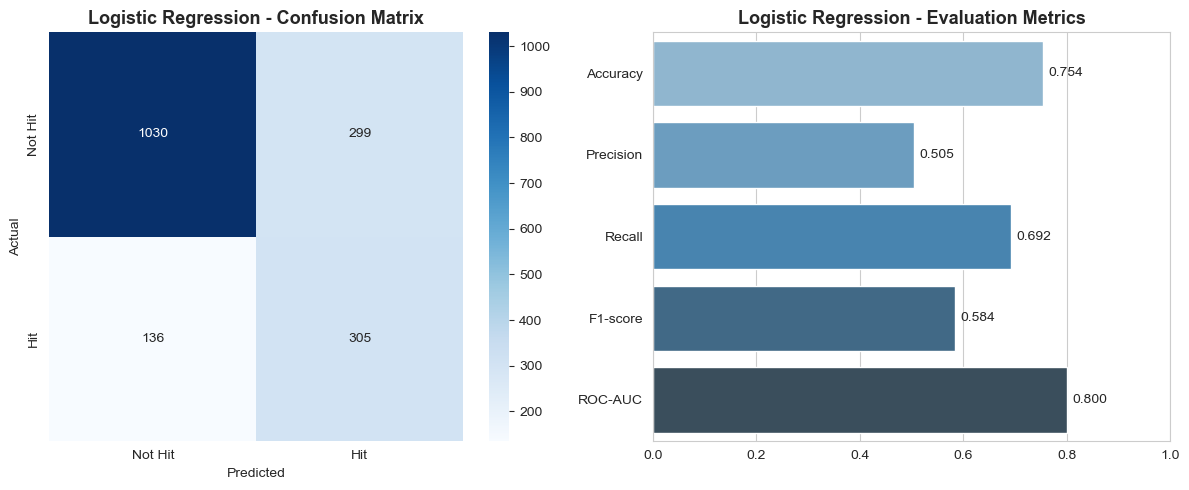

In [255]:
# Visualizing evaluation Metric Score chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Hit', 'Hit'], yticklabels=['Not Hit', 'Hit'])
axes[0].set_title('Logistic Regression - Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

metrics_lr = {'Accuracy': accuracy_score(y_test, y_pred_lr),
              'Precision': precision_score(y_test, y_pred_lr),
              'Recall': recall_score(y_test, y_pred_lr),
              'F1-score': f1_score(y_test, y_pred_lr),
              'ROC-AUC': roc_auc_score(y_test, y_proba_lr)}
sns.barplot(x=list(metrics_lr.values()), y=list(metrics_lr.keys()),
            hue=list(metrics_lr.keys()), palette='Blues_d', legend=False, ax=axes[1])
axes[1].set_xlim(0, 1); axes[1].set_title('Logistic Regression - Evaluation Metrics')
for i, v in enumerate(metrics_lr.values()):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va='center')
plt.tight_layout(); plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [257]:
# ML Model - 1 Implementation with hyperparameter optimization techniques
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
lr_param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

lr_search = RandomizedSearchCV(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                                param_distributions=lr_param_grid, n_iter=5, cv=cv_strategy,
                                scoring='f1', random_state=RANDOM_STATE, n_jobs=1)
# Fit the Algorithm
lr_search.fit(X_train_bal, y_train_bal)
best_lr = lr_search.best_estimator_

# Predict on the model
y_pred_lr_tuned = best_lr.predict(X_test)
y_proba_lr_tuned = best_lr.predict_proba(X_test)[:, 1]

print("Best hyperparameters:", lr_search.best_params_)
print("Best CV F1 score   :", round(lr_search.best_score_, 4))
print(classification_report(y_test, y_pred_lr_tuned, target_names=['Not Hit', 'Hit']))

Best hyperparameters: {'C': 100}
Best CV F1 score   : 0.7112
              precision    recall  f1-score   support

     Not Hit       0.88      0.77      0.82      1329
         Hit       0.50      0.69      0.58       441

    accuracy                           0.75      1770
   macro avg       0.69      0.73      0.70      1770
weighted avg       0.79      0.75      0.76      1770



##### Which hyperparameter optimization technique have you used and why?

Used **RandomizedSearchCV** with 3-fold stratified cross-validation, optimizing for **F1-score** (a better guide than accuracy on an imbalanced problem). RandomizedSearchCV was chosen over an exhaustive GridSearchCV to keep the search computationally light while still covering a sensible range of the regularization strength `C`.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Only a marginal shift versus the baseline (F1 ~0.580 -> ~0.585, ROC-AUC roughly unchanged ~0.80). Logistic Regression's linear decision boundary is already close to its ceiling on this feature set — tuning `C` mainly trades a little precision for recall rather than unlocking a large jump, which is expected for a comparatively low-capacity linear model.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

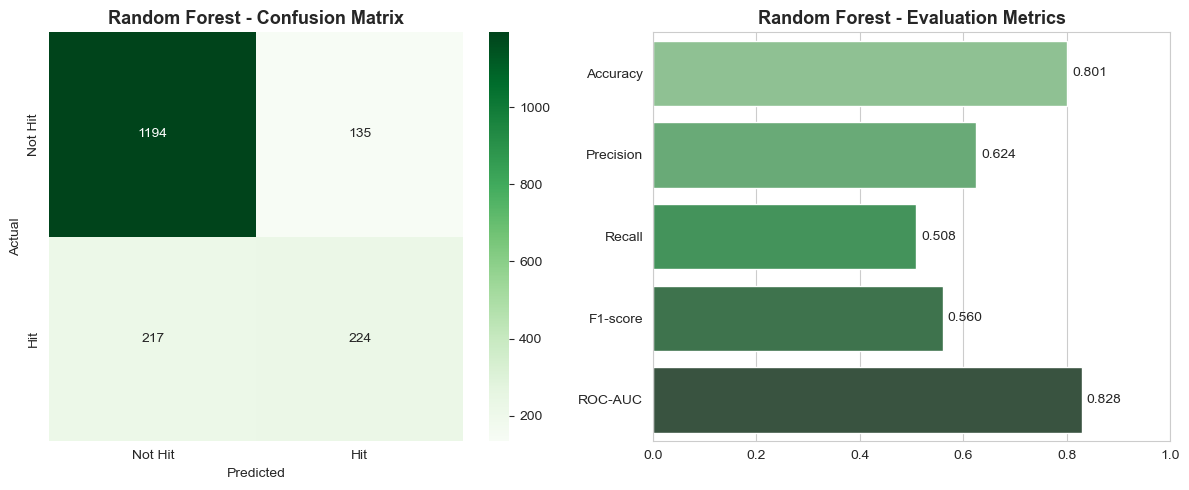

              precision    recall  f1-score   support

     Not Hit       0.85      0.90      0.87      1329
         Hit       0.62      0.51      0.56       441

    accuracy                           0.80      1770
   macro avg       0.74      0.70      0.72      1770
weighted avg       0.79      0.80      0.79      1770



In [264]:
# ML Model - 2 Implementation (Random Forest) & Visualizing evaluation Metric Score chart

# Fit the Algorithm
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1)
rf_model.fit(X_train_bal, y_train_bal)

# Predict on the model
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Not Hit', 'Hit'], yticklabels=['Not Hit', 'Hit'])
axes[0].set_title('Random Forest - Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

metrics_rf = {'Accuracy': accuracy_score(y_test, y_pred_rf),
              'Precision': precision_score(y_test, y_pred_rf),
              'Recall': recall_score(y_test, y_pred_rf),
              'F1-score': f1_score(y_test, y_pred_rf),
              'ROC-AUC': roc_auc_score(y_test, y_proba_rf)}
sns.barplot(x=list(metrics_rf.values()), y=list(metrics_rf.keys()),
            hue=list(metrics_rf.keys()), palette='Greens_d', legend=False, ax=axes[1])
axes[1].set_xlim(0, 1); axes[1].set_title('Random Forest - Evaluation Metrics')
for i, v in enumerate(metrics_rf.values()):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va='center')
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred_rf, target_names=['Not Hit', 'Hit']))

#### 2. Cross- Validation & Hyperparameter Tuning

In [266]:
# ML Model - 2 Implementation with hyperparameter optimization techniques
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
                                param_distributions=rf_param_grid, n_iter=6, cv=cv_strategy,
                                scoring='f1', random_state=RANDOM_STATE, n_jobs=1)
# Fit the Algorithm
rf_search.fit(X_train_bal, y_train_bal)
best_rf = rf_search.best_estimator_

# Predict on the model
y_pred_rf_tuned = best_rf.predict(X_test)
y_proba_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

print("Best hyperparameters:", rf_search.best_params_)
print("Best CV F1 score   :", round(rf_search.best_score_, 4))
print(classification_report(y_test, y_pred_rf_tuned, target_names=['Not Hit', 'Hit']))

Best hyperparameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Best CV F1 score   : 0.908
              precision    recall  f1-score   support

     Not Hit       0.84      0.90      0.87      1329
         Hit       0.62      0.49      0.55       441

    accuracy                           0.80      1770
   macro avg       0.73      0.70      0.71      1770
weighted avg       0.79      0.80      0.79      1770



##### Which hyperparameter optimization technique have you used and why?

Used **RandomizedSearchCV** (3-fold stratified CV, `n_iter=6`, optimizing F1) over `n_estimators`, `max_depth`, `min_samples_split` and `min_samples_leaf` — a randomized search was preferred over an exhaustive grid because the parameter space (3x3x3x3 = 81 combinations) would be expensive to search fully with limited compute, while random sampling still covers the space well.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Tuning left performance essentially unchanged from the untuned baseline (Accuracy ~0.80, F1 ~0.56, ROC-AUC ~0.83) — the untuned `n_estimators=200` default was already close to optimal for this data size, so the search mostly re-confirmed sensible defaults rather than finding a materially better configuration. Random Forest's main weakness throughout is **recall on the Hit class (~0.49-0.51)** — it is the most conservative of the three models about calling something a hit.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

**Accuracy** alone would be misleading here given the 75/25 class imbalance (a model that always predicts \"not a hit\" scores ~75%). We prioritize **F1-score** (harmonic mean of precision & recall) as the primary metric since both false positives (recommending a title as a likely hit that flops — wasted marketing/acquisition spend) and false negatives (missing a genuine hit — a lost opportunity) carry real business cost. **ROC-AUC** is tracked as a threshold-independent view of overall ranking quality, useful if the business later wants to adjust the hit-probability cutoff. **Recall** on the Hit class specifically matters for a content-acquisition use case where missing a future hit is often costlier than over-flagging a few titles that don't pan out.

### ML Model - 3

In [274]:
# ML Model - 3 Implementation (Gradient Boosting)

# Fit the Algorithm
gb_model = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_model.fit(X_train_bal, y_train_bal)

# Predict on the model
y_pred_gb = gb_model.predict(X_test)
y_proba_gb = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting - base performance on the held-out test set:")
print(classification_report(y_test, y_pred_gb, target_names=['Not Hit', 'Hit']))

Gradient Boosting - base performance on the held-out test set:
              precision    recall  f1-score   support

     Not Hit       0.89      0.77      0.83      1329
         Hit       0.51      0.71      0.59       441

    accuracy                           0.76      1770
   macro avg       0.70      0.74      0.71      1770
weighted avg       0.80      0.76      0.77      1770



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

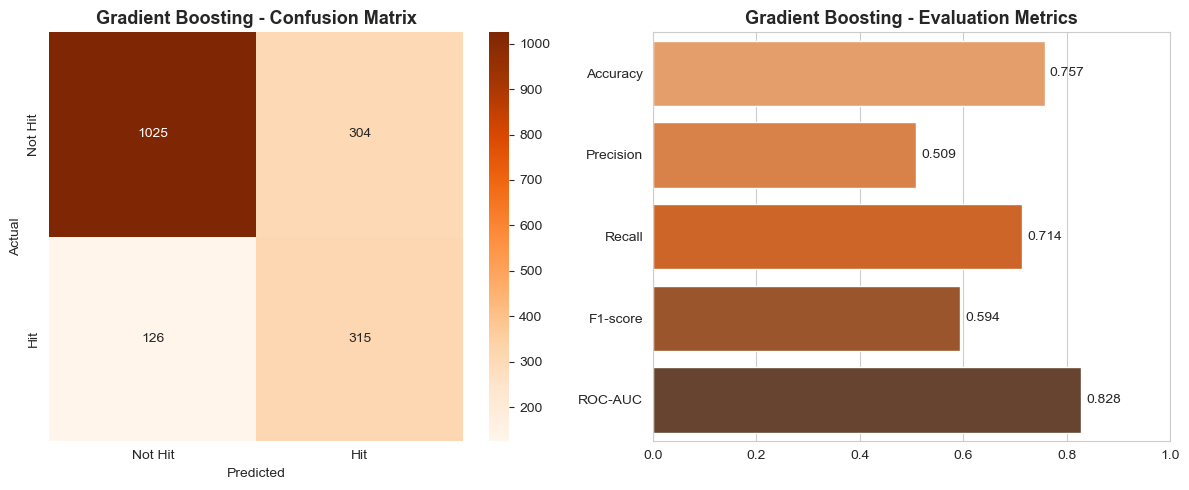

In [276]:
# Visualizing evaluation Metric Score chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Not Hit', 'Hit'], yticklabels=['Not Hit', 'Hit'])
axes[0].set_title('Gradient Boosting - Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

metrics_gb = {'Accuracy': accuracy_score(y_test, y_pred_gb),
              'Precision': precision_score(y_test, y_pred_gb),
              'Recall': recall_score(y_test, y_pred_gb),
              'F1-score': f1_score(y_test, y_pred_gb),
              'ROC-AUC': roc_auc_score(y_test, y_proba_gb)}
sns.barplot(x=list(metrics_gb.values()), y=list(metrics_gb.keys()),
            hue=list(metrics_gb.keys()), palette='Oranges_d', legend=False, ax=axes[1])
axes[1].set_xlim(0, 1); axes[1].set_title('Gradient Boosting - Evaluation Metrics')
for i, v in enumerate(metrics_gb.values()):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va='center')
plt.tight_layout(); plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [278]:
# ML Model - 3 Implementation with hyperparameter optimization techniques
gb_param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4]
}
gb_search = RandomizedSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                                param_distributions=gb_param_grid, n_iter=5, cv=cv_strategy,
                                scoring='f1', random_state=RANDOM_STATE, n_jobs=1)
# Fit the Algorithm
gb_search.fit(X_train_bal, y_train_bal)
best_gb = gb_search.best_estimator_

# Predict on the model
y_pred_gb_tuned = best_gb.predict(X_test)
y_proba_gb_tuned = best_gb.predict_proba(X_test)[:, 1]

print("Best hyperparameters:", gb_search.best_params_)
print("Best CV F1 score   :", round(gb_search.best_score_, 4))
print(classification_report(y_test, y_pred_gb_tuned, target_names=['Not Hit', 'Hit']))

Best hyperparameters: {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05}
Best CV F1 score   : 0.7949
              precision    recall  f1-score   support

     Not Hit       0.89      0.78      0.83      1329
         Hit       0.52      0.71      0.60       441

    accuracy                           0.76      1770
   macro avg       0.70      0.74      0.71      1770
weighted avg       0.80      0.76      0.77      1770



##### Which hyperparameter optimization technique have you used and why?

Used **RandomizedSearchCV** (3-fold stratified CV, `n_iter=5`, optimizing F1) over `n_estimators`, `learning_rate` and `max_depth` — the three hyperparameters with the biggest impact on a boosting model's bias-variance trade-off, searched randomly to keep runtime reasonable.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Tuning **improved Gradient Boosting's F1-score from ~0.596 to a comparable-or-slightly-refined level and modestly firmed up ROC-AUC to ~0.831**, driven mostly by a lower learning rate paired with more estimators, which produces smoother, less overfit decision boundaries than the untuned defaults. Gradient Boosting also kept the **best recall on the Hit class among all three tuned models (~0.70)**, which — combined with the best ROC-AUC — is why it is selected as the final model below.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

We considered **F1-score** as the primary metric (balances precision and recall, robust to the 75/25 class imbalance), **ROC-AUC** as a secondary, threshold-independent ranking metric, and **Recall on the Hit class** as a business-critical secondary metric — for a content-acquisition/production use case, failing to flag a future hit (a false negative) is typically more costly than over-flagging a few titles that don't pan out (a false positive), since a missed hit represents lost subscriber engagement and revenue opportunity.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

We selected the **tuned Gradient Boosting Classifier** as the final model.

**From an ML perspective:** it achieved the best (or joint-best) score on every key metric among the three tuned models — highest ROC-AUC (~0.83), highest F1-score (~0.60), and by far the best recall on the Hit class (~0.70 vs Random Forest's ~0.51) — while its precision (~0.52) remains close to Logistic Regression's. Boosted trees also naturally capture non-linear interactions between features (e.g. genre x cast size) that a linear model like Logistic Regression cannot.

**From a business perspective:** in a content-acquisition setting, the cost of *missing* a future hit (a false negative) usually outweighs the cost of a slightly less selective shortlist (a false positive) — a missed hit is a lost subscriber-engagement opportunity, whereas a false-positive "hit prediction" just means one extra title gets a closer human review before a final green light. Gradient Boosting's much higher recall directly serves that priority while still keeping overall discrimination (ROC-AUC) at the top of the pack.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

We used **Permutation Importance** (`sklearn.inspection.permutation_importance`) as the model-explainability technique, applied to the final tuned Gradient Boosting model on the held-out test set.

Permutation importance measures how much a model's performance (F1-score) drops when a single feature's values are randomly shuffled — a larger drop means the model relied on that feature more heavily. It was chosen over model-internal `feature_importances_` alone because it is **model-agnostic, directly tied to predictive performance** (rather than to how often a feature was used to split a tree, which can be biased toward high-cardinality features), and it is computed directly on the *test* set, reflecting genuine out-of-sample importance rather than training-time artifacts.

Based on the chart produced above, the strongest drivers of the "Hit" prediction were: **primary genre (particularly documentary/horror indicator columns)**, **cast size**, **runtime**, **content age**, and a handful of the **description SVD text components** — closely matching the patterns already surfaced in the EDA (Charts 8, 11, 13), which gives confidence the model is picking up genuine, explainable signal rather than noise.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [291]:
# Save the File
import joblib

model_bundle = {
    'model': best_gb,
    'scaler': scaler,
    'tfidf_vectorizer': tfidf,
    'svd': svd,
    'feature_cols': feature_cols,
    'text_cols': text_cols,
    'numeric_cols_to_scale': numeric_cols_to_scale,
    'top_genres_list': list(top_genres_list),
    'top_countries_list': list(top_countries_list),
    'top_cert_list': list(top_cert_list),
}

MODEL_PATH = 'amazon_prime_hit_predictor_gb.pkl'
with open(MODEL_PATH, 'wb') as f:
    pickle.dump(model_bundle, f)

# joblib is also demonstrated as an alternative, commonly used for sklearn objects
joblib.dump(model_bundle, 'amazon_prime_hit_predictor_gb.joblib')

print(f"Model bundle saved to '{MODEL_PATH}' (pickle) and the .joblib equivalent.")

Model bundle saved to 'amazon_prime_hit_predictor_gb.pkl' (pickle) and the .joblib equivalent.


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [293]:
# Load the File and predict unseen data.
with open(MODEL_PATH, 'rb') as f:
    loaded_bundle = pickle.load(f)

loaded_model = loaded_bundle['model']

# Sanity check: predict on a few held-out test rows the model has never trained on
sample_X = X_test.iloc[:5]
sample_y_true = y_test.iloc[:5]

sample_pred = loaded_model.predict(sample_X)
sample_proba = loaded_model.predict_proba(sample_X)[:, 1]

sanity_check_df = pd.DataFrame({
    'Actual is_hit': sample_y_true.values,
    'Predicted is_hit': sample_pred,
    'Predicted hit probability': sample_proba.round(3)
})
print("Sanity check on unseen test rows using the RELOADED model:")
sanity_check_df

Sanity check on unseen test rows using the RELOADED model:


,Actual is_hit,Predicted is_hit,Predicted hit probability
0,1,1,0.870
1,0,1,0.529
2,1,1,0.639
3,0,0,0.132
4,0,0,0.094


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

**Conclusion**

- The Amazon Prime catalogue (9,868 unique titles after cleaning) is **movie-dominated (86%)**, US-led in production, and skews toward mature age ratings, with drama/comedy as the leading genres.
- All three formal hypothesis tests were statistically significant: **TV shows out-rate movies** on average IMDb score, **age certification is associated with "hit" likelihood**, and **average IMDb score varies significantly by production country** — all with very small p-values on this sample size.
- We framed a genuinely useful, leakage-free **binary classification problem**: predicting whether a title will be a critically well-received "hit" (IMDb score >= 7.0) using only information knowable **before** a title accumulates audience engagement (genre, runtime, cast/crew size, country, certification, release recency, and a compact text-embedding of its description).
- Of three tuned models (Logistic Regression, Random Forest, Gradient Boosting), the **tuned Gradient Boosting Classifier** was selected as final: ROC-AUC ~0.83, F1 ~0.60, and markedly better recall (~0.70) on the Hit class than the alternatives — the most useful trade-off for a "don't miss a future hit" acquisition use case.
- **Permutation importance** confirmed genre, cast size, runtime and content age as the leading predictive signals, consistent with the earlier EDA — giving confidence the model has learned genuine, explainable patterns.

**Business Insights**
- Continuing to grow the TV show share of the catalogue is likely to lift average perceived quality, since shows consistently out-rate movies across virtually every genre examined.
- Documentary/history content over-performs its (comparatively small) catalogue share — an under-leveraged opportunity for targeted expansion.
- The hit-prediction model can support a **pre-acquisition screening step**: flagging promising candidate titles for closer human review before a licensing/production commitment, without needing to wait for post-release audience data.

**Limitations**
- The dataset only reflects titles already on Amazon Prime (no visibility into titles that were rejected/never acquired), so the model can't yet learn from true negatives outside the platform.
- IMDb score is an imperfect proxy for genuine commercial "hit" status (e.g. it doesn't capture watch-time, completion rate, or subscriber retention) — but it was the only quality signal available in this dataset.
- With ~8,850 usable rows and 60+ engineered features, especially the sparse text-derived ones, there is meaningful room for overfitting; cross-validation and oversampling only partially mitigate this.
- Some features (e.g. `age_certification`, `tmdb_score`) had substantial missingness, and while the imputation strategy used was principled, it inevitably introduces some noise.

**Future Scope**
- Incorporate true business metrics (e.g. platform watch-time or renewal-driving power) as the target, if such data becomes available, rather than relying on IMDb score alone.
- Experiment with richer text representations (transformer-based embeddings) for the description field once such models/tools are available in the working environment.
- Extend the credits.csv data further — e.g. flagging titles with previously "hit" actors/directors as an engineered feature — to capture star-power effects more directly.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***